# Phase II: Data Wrangling & EDA — Lower Ninth Ward vs. New Orleans
**Mastercard Inclusive Growth Score (IGS)** · tract-level data, 2017–2025

**Question:** How does the Lower Ninth Ward compare to the rest of Orleans Parish in Inclusive Growth, and which factors are most responsible for the disparity?

| Term | Meaning in this notebook |
|---|---|
| **Study area ("Lower 9th export")** | Every tract returned by the IGS dashboard for the Lower Ninth Ward export (one of them lies across the line in St. Bernard Parish) |
| **Rest of Orleans** | All other Orleans Parish tracts in the New Orleans export |
| **Pillars** | Place · Economy · Community (Growth and Inclusion are the other two cuts of the score) |

**Notebook map:** 1 Load & clean → 2 Data-quality audit → 3 Define groups → 4 Seven visualizations → 5 Statistical tests → 6 Findings → 7 Phase III handoff

**To run in Colab:** upload both CSV exports when prompted (or put them in the same folder). The notebook works out which is which by tract count and writes the cleaned files to `clean_data/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

# ---- palette: validated reference palette. Blue = study area, orange = rest of Orleans (fixed for every chart)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)

# ---- config
YEAR = 2025                                   # cross-section used for group comparisons
OUT_DIR = Path("clean_data"); OUT_DIR.mkdir(exist_ok=True)
STUDY, REST, OUTSIDE = "Lower 9th export", "Rest of Orleans", "Outside Orleans"
CORE_TRACTS = ["22071000901", "22071000902", "22071000903", "22071000904"]   # tracts 9.01-9.04: sensitivity check only (not verified against a Census map)

def headline(ax, text, sub=None):
    """Takeaway title with an optional one-line subtitle."""
    ax.set_title(text, loc="left", pad=30 if sub else 12)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.5, color=INK2)

# ---- small stats helpers
def cliffs_delta(a, b):
    """P(a > b) - P(a < b); -1..+1, negative means a tends to be lower than b."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return ((a[:, None] > b[None, :]).sum() - (a[:, None] < b[None, :]).sum()) / (len(a) * len(b))

def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, float); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def boot_ci(a, b, stat=np.mean, B=5000, seed=42):
    """95% bootstrap CI for stat(a) - stat(b), resampling tracts within each group."""
    rng = np.random.default_rng(seed); a, b = np.asarray(a, float), np.asarray(b, float)
    d = [stat(rng.choice(a, len(a))) - stat(rng.choice(b, len(b))) for _ in range(B)]
    return np.percentile(d, [2.5, 97.5])

## 1. Load & clean  *(Data Architect)*
Each export has a **two-row header** (row 1 = section: Place/Economy/Community, row 2 = column name) plus a blank spacer row, so a plain `read_csv` mislabels everything. One function cleans both files so they can't drift apart. **No imputation happens here**: missing values stay missing so that Phase III can impute inside cross-validation folds without leaking information.

In [2]:
# ---------- locate the two exports ----------
PATTERN = "Inclusive_Growth_Score_Data_Export*.csv"
SEARCH_DIRS = [Path("."), Path("raw"), Path("data"), Path("/content"), Path("/content/data")]

def find_exports():
    return sorted({p.resolve() for d in SEARCH_DIRS if d.exists() for p in d.glob(PATTERN)})

def read_export(path):
    """Rebuild the two-row header and drop the blank spacer row. Returns (frame, {column: section})."""
    raw = pd.read_csv(path, header=None, dtype=str)
    section = raw.iloc[0].ffill()
    names = raw.iloc[1]
    df = raw.iloc[2:].copy()
    df.columns = [n if isinstance(n, str) else "row_id" for n in names]
    df = df.drop(columns="row_id")
    df = df[df["Census Tract FIPS code"].notna()].reset_index(drop=True)
    return df, {n: s for n, s in zip(names, section) if isinstance(n, str)}

paths = find_exports()
if len(paths) < 2:
    try:
        from google.colab import files
        print("Upload BOTH IGS exports (the Lower 9th export and the New Orleans export).")
        files.upload()
        paths = find_exports()
    except ImportError:
        pass
assert len(paths) >= 2, "Put both IGS export CSVs next to this notebook (or in ./raw)."

n_tracts = {p: read_export(p)[0]["Census Tract FIPS code"].nunique() for p in paths}
L9_PATH, NO_PATH = min(n_tracts, key=n_tracts.get), max(n_tracts, key=n_tracts.get)
assert n_tracts[L9_PATH] < n_tracts[NO_PATH], "Both files have the same number of tracts, so I can't tell which is which."
print(f"Lower 9th export  : {L9_PATH.name}  ({n_tracts[L9_PATH]} tracts)")
print(f"New Orleans export: {NO_PATH.name}  ({n_tracts[NO_PATH]} tracts)")

Lower 9th export  : Inclusive_Growth_Score_Data_Export_20-11-2026_181802_Compared_to_Urban-Rural.csv  (35 tracts)
New Orleans export: Inclusive_Growth_Score_Data_Export_20-11-2026_185758Compared_to_Urban-Rural.csv  (209 tracts)


In [3]:
# ---------- one cleaning function for both files ----------
META_TEXT = ["Is an Opportunity Zone", "Census Tract FIPS code", "County", "State", "OZ 2.0 Eligible"]
RENAME = {"Census Tract FIPS code": "fips", "County": "parish", "State": "state", "Year": "year",
          "Is an Opportunity Zone": "is_opportunity_zone", "OZ 2.0 Eligible": "oz2_eligible",
          "Inclusive Growth Score": "igs", "Growth": "growth", "Inclusion": "inclusion"}

def snake(col):
    if col in RENAME: return RENAME[col]
    s = col.lower().replace(", %", "_pct").replace("/", " ")
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")

def tract_label(fips):                          # 22071000904 -> '9.04', 22071002000 -> '20'
    s = fips[-6:]; whole, dec = int(s[:4]), s[4:]
    return f"{whole}" if dec == "00" else f"{whole}.{dec}"

def clean_export(path, study_fips):
    raw, sections = read_export(path)
    log = [("1 Parse header", f"Rebuilt the two-row header and dropped the blank spacer row: {len(raw)} tract-year rows x {raw.shape[1]} columns.")]

    coerced = 0
    for c in raw.columns:
        if c in META_TEXT: continue
        v = pd.to_numeric(raw[c], errors="coerce")
        coerced += int((raw[c].notna() & v.isna()).sum())
        raw[c] = v
    log.append(("2 Types", f"Converted every score/percentage column to numbers ({coerced} non-numeric cells became missing)."))

    empty = [c for c in raw.columns if c not in META_TEXT and raw[c].isna().all()]
    raw = raw.drop(columns=empty)
    log.append(("3 Empty columns", f"Dropped {len(empty)} columns that are blank in every row: " + (", ".join(empty) or "none") + "."))

    any_igs = raw.groupby("Census Tract FIPS code")["Inclusive Growth Score"].apply(lambda s: s.notna().any())
    dropped = any_igs[~any_igs].index.tolist()
    det = raw[raw["Census Tract FIPS code"].isin(dropped)].drop_duplicates("Census Tract FIPS code")
    txt = "; ".join(f"{r['Census Tract FIPS code']} ({r['County']})" for _, r in det.iterrows()) or "none"
    raw = raw[~raw["Census Tract FIPS code"].isin(dropped)]
    log.append(("4 Unscored tracts", f"Dropped {len(dropped)} tracts with no Inclusive Growth Score in any year (nothing to analyze): {txt}."))

    meta = {"pretty": {snake(c): (c[:-6] if c.endswith(" Score") else c) for c in raw.columns},
            "pillar": {snake(c): sections.get(c, "").lower() for c in raw.columns}}
    df = raw.rename(columns=snake)
    df["year"] = df["year"].astype(int)
    df["is_opportunity_zone"] = df["is_opportunity_zone"].eq("Yes")
    df["oz2_eligible"] = df["oz2_eligible"].eq("Yes")
    df["parish"] = df["parish"].str.replace(" Parish", "", regex=False)
    df["tract"] = df["fips"].map(tract_label)
    df["area_group"] = np.where(df["fips"].isin(study_fips), STUDY, np.where(df["parish"].eq("Orleans"), REST, OUTSIDE))
    df["core_9_01_to_9_04"] = df["fips"].isin(CORE_TRACTS)
    ids = ["fips", "tract", "parish", "state", "year", "area_group", "core_9_01_to_9_04", "is_opportunity_zone", "oz2_eligible"]
    df = df[ids + [c for c in df.columns if c not in ids]].sort_values(["fips", "year"]).reset_index(drop=True)
    log.append(("5 Names & flags", "snake_case column names; Yes/blank flags -> True/False; 'Parish' suffix removed; added readable tract label, area_group, and core_9_01_to_9_04 (sensitivity flag)."))

    # ---- validation (fails loudly if a future export breaks an assumption)
    assert not df.duplicated(["fips", "year"]).any(), "duplicate tract-year rows"
    yrs = df.groupby("fips")["year"].agg(["min", "max", "nunique"])
    assert (yrs["nunique"] == yrs["max"] - yrs["min"] + 1).all() and yrs["nunique"].nunique() == 1, "gaps in the year series"
    top = ["igs", "growth", "inclusion", "place", "economy", "community"]
    assert df[top].notna().all().all(), "missing headline scores remain"
    sc = [c for c in df.columns if c.endswith("_score")] + top
    v = df[sc].to_numpy(float)
    assert np.nanmin(v) >= 0 and np.nanmax(v) <= 100, "score outside 0-100"
    ind = [c for c in df.columns if c.endswith("_score")]
    log.append(("6 Missing values kept", f"{int(df[ind].isna().sum().sum())} indicator-score cells are still missing and were left missing (no imputation here)."))
    log.append(("Result", f"{df.fips.nunique()} tracts x {df.year.nunique()} years = {len(df)} rows, {df.shape[1]} columns. Checks passed: unique tract-year keys, complete year series, headline scores present, all scores within 0-100."))
    return df, pd.DataFrame(log, columns=["step", "what_was_done"]), meta

l9_fips = set(read_export(L9_PATH)[0]["Census Tract FIPS code"])
no, log_no, meta = clean_export(NO_PATH, l9_fips)
l9, log_l9, _ = clean_export(L9_PATH, l9_fips)

# ---- cross-check: the Lower 9th export must match its tracts inside the New Orleans export, cell for cell
common = [c for c in l9.columns if c in no.columns]
a = l9[common].sort_values(["fips", "year"]).reset_index(drop=True)
b = no[no.fips.isin(l9.fips)][common].sort_values(["fips", "year"]).reset_index(drop=True)
num = a.select_dtypes("number").columns
assert a.shape == b.shape and np.allclose(a[num].to_numpy(float), b[num].to_numpy(float), equal_nan=True) and a.drop(columns=num).equals(b.drop(columns=num))
print("Cross-check passed: the Lower 9th export is identical to its tracts in the New Orleans export.")

# ---- save cleaned datasets + cleaning log
l9.to_csv(OUT_DIR / "igs_lower9th_clean.csv", index=False)
no.to_csv(OUT_DIR / "igs_new_orleans_clean.csv", index=False)
cleaning_log = pd.concat([log_l9.assign(file="Lower 9th export"), log_no.assign(file="New Orleans export")])[["file", "step", "what_was_done"]]
cleaning_log.to_csv(OUT_DIR / "igs_cleaning_log.csv", index=False)

pd.set_option("display.max_colwidth", 220)
display(cleaning_log.reset_index(drop=True))

Cross-check passed: the Lower 9th export is identical to its tracts in the New Orleans export.


,file,step,what_was_done
0,Lower 9th export,1 Parse header,Rebuilt the two-row header and dropped the blank spacer row: 315 tract-year rows x 72 columns.
1,Lower 9th export,2 Types,Converted every score/percentage column to numbers (0 non-numeric cells became missing).
2,Lower 9th export,3 Empty columns,"Dropped 4 columns that are blank in every row: Spend Growth Base, %, Spend Growth Tract, %, Spending per Capita Base, %, Spending per Capita Tract, %."
3,Lower 9th export,4 Unscored tracts,Dropped 2 tracts with no Inclusive Growth Score in any year (nothing to analyze): 22071001600 (Orleans Parish); 22071980100 (Orleans Parish).
4,Lower 9th export,5 Names & flags,"snake_case column names; Yes/blank flags -> True/False; 'Parish' suffix removed; added readable tract label, area_group, and core_9_01_to_9_04 (sensitivity flag)."
5,Lower 9th export,6 Missing values kept,196 indicator-score cells are still missing and were left missing (no imputation here).
6,Lower 9th export,Result,"33 tracts x 9 years = 297 rows, 71 columns. Checks passed: unique tract-year keys, complete year series, headline scores present, all scores within 0-100."
7,New Orleans export,1 Parse header,Rebuilt the two-row header and dropped the blank spacer row: 1881 tract-year rows x 72 columns.
8,New Orleans export,2 Types,Converted every score/percentage column to numbers (0 non-numeric cells became missing).
9,New Orleans export,3 Empty columns,"Dropped 4 columns that are blank in every row: Spend Growth Base, %, Spend Growth Tract, %, Spending per Capita Base, %, Spending per Capita Tract, %."


## 2. Data-quality audit *(Data Architect)*
What is still imperfect after cleaning, and what it means for analysis and modeling.

In [4]:
IND = [c for c in no.columns if c.endswith("_score")]                     # 18 indicator scores
PRETTY, PILLAR_OF = meta["pretty"], meta["pillar"]
PILLARS = ["place", "economy", "community"]
LABEL = {"igs": "Inclusive Growth Score", "place": "Place", "economy": "Economy", "community": "Community", "growth": "Growth", "inclusion": "Inclusion"}

# 1) Missing indicator scores, by group
miss = pd.DataFrame({g: no[no.area_group == g][IND].isna().mean() * 100 for g in [STUDY, REST, OUTSIDE]}).round(1)
miss.index = [f"{PILLAR_OF[c].title()} · {PRETTY[c]}" for c in miss.index]
miss.columns = [f"% missing: {c}" for c in miss.columns]
print("Indicators with missing values (share of tract-years):")
display(miss[(miss > 0).any(axis=1)].sort_values(miss.columns[0], ascending=False))

# 2) Indicators that never change within a tract
nuniq = no.groupby("fips")[IND].nunique().max()
static = [PRETTY[c] for c in nuniq[nuniq <= 1].index]
print("\nIndicators that never change over time in any tract:", static or "none")

# 3) Benchmark ("Base") columns: one value per year for all tracts?
base = [c for c in no.columns if "_base" in c]
flat = [c for c in base if no.groupby("year")[c].nunique().max() <= 1]
print(f"{len(flat)} of {len(base)} Base (benchmark) columns have a single value per year across ALL tracts -> they cannot differentiate tracts.")
last3 = no.groupby("year")[flat].first().loc[[2023, 2024, 2025]].nunique()
print(f"{int((last3 == 1).sum())} of those {len(flat)} are also identical for 2023, 2024 and 2025 (possible carry-forward).")

# 4) Is the overall score just the average of the three pillars?
dev = (no["igs"] - no[PILLARS].mean(axis=1)).abs()
print(f"\nIGS vs. average of Place/Economy/Community: mean abs. difference {dev.mean():.2f}, max {dev.max():.1f} points (small differences, likely rounding).")
print("-> The pillar contribution chart in section 4 is therefore a valid way to split the gap.")

# 5) Do the pillars equal the average of their indicator scores?
for p in PILLARS:
    cols = [c for c in IND if PILLAR_OF[c] == p]
    d = (no[p] - no[cols].mean(axis=1)).abs().mean()
    print(f"{p.title():<9} vs. plain average of its {len(cols)} indicator scores: mean abs. difference {d:.1f} points")
print("-> Indicators are weighted (or scaled) in ways the export does not show, so points cannot be assigned to single indicators exactly.")

Indicators with missing values (share of tract-years):


,% missing: Lower 9th export,% missing: Rest of Orleans,% missing: Outside Orleans
Economy · Minority/Women Owned Businesses,37.0,26.2,2.7
Economy · Spend Growth,12.1,9.4,0.0
Community · Spending per Capita,12.1,9.4,0.0
Economy · New Businesses,3.0,0.7,0.0
Place · Residential Real Estate Value,1.7,5.5,0.0
Place · Affordable Housing,0.0,0.7,0.0
Place · Internet Access,0.0,0.7,0.0
Place · Travel Time to Work,0.0,0.7,0.0
Economy · Labor Market Engagement Index,0.0,0.7,0.0
Economy · Small Business Loans,0.0,1.3,0.0



Indicators that never change over time in any tract: ['Acres of Park Land']
13 of 16 Base (benchmark) columns have a single value per year across ALL tracts -> they cannot differentiate tracts.
11 of those 13 are also identical for 2023, 2024 and 2025 (possible carry-forward).

IGS vs. average of Place/Economy/Community: mean abs. difference 0.34, max 1.3 points (small differences, likely rounding).
-> The pillar contribution chart in section 4 is therefore a valid way to split the gap.
Place     vs. plain average of its 6 indicator scores: mean abs. difference 3.1 points
Economy   vs. plain average of its 6 indicator scores: mean abs. difference 1.4 points
Community vs. plain average of its 6 indicator scores: mean abs. difference 3.5 points
-> Indicators are weighted (or scaled) in ways the export does not show, so points cannot be assigned to single indicators exactly.


## 3. Define the groups

In [5]:
cur = no[no.year == YEAR]
study = cur[cur.area_group == STUDY]
rest = cur[cur.area_group == REST]

grp = (no.drop_duplicates("fips").groupby(["area_group", "parish"]).size().rename("tracts").reset_index())
display(grp)
print(f"\nStudy area: {len(study)} tracts ({int((study.parish == 'Orleans').sum())} Orleans + {int((study.parish != 'Orleans').sum())} outside Orleans) | Rest of Orleans: {len(rest)} tracts | {YEAR} cross-section")

sens = {
    "Study area (all tracts in the Lower 9th export)": study,
    "Study area, Orleans tracts only": study[study.parish == "Orleans"],
    "Core tracts 9.01-9.04 only (unverified)": cur[cur.fips.isin(CORE_TRACTS)],
    "Rest of Orleans (comparison)": rest,
}
sens_tbl = pd.DataFrame({k: {"tracts": len(v), **{LABEL[c]: round(v[c].mean(), 1) for c in ["igs", "place", "economy", "community"]}} for k, v in sens.items()}).T
print(f"\nSensitivity: {YEAR} group means under different definitions of 'Lower Ninth Ward'")
display(sens_tbl)

,area_group,parish,tracts
0,Lower 9th export,Orleans,32
1,Lower 9th export,St. Bernard,1
2,Outside Orleans,Jefferson,16
3,Outside Orleans,Plaquemines,2
4,Outside Orleans,St. Bernard,5
5,Outside Orleans,St. Tammany,2
6,Rest of Orleans,Orleans,149



Study area: 33 tracts (32 Orleans + 1 outside Orleans) | Rest of Orleans: 149 tracts | 2025 cross-section

Sensitivity: 2025 group means under different definitions of 'Lower Ninth Ward'


,tracts,Inclusive Growth Score,Place,Economy,Community
Study area (all tracts in the Lower 9th export),33.0,35.7,34.6,34.8,37.7
"Study area, Orleans tracts only",32.0,35.7,34.5,35.2,37.6
Core tracts 9.01-9.04 only (unverified),4.0,28.1,32.5,23.2,27.5
Rest of Orleans (comparison),149.0,42.6,43.4,41.1,43.0


## 4. Visualizations  *(Lead Analyst + Communications Lead)*
Colors are fixed for the whole notebook: **blue = Lower 9th export, orange = rest of Orleans**. Each chart title states the finding, and the table under the key charts holds the same numbers.

### Fig 1 — Inclusive Growth Score over time

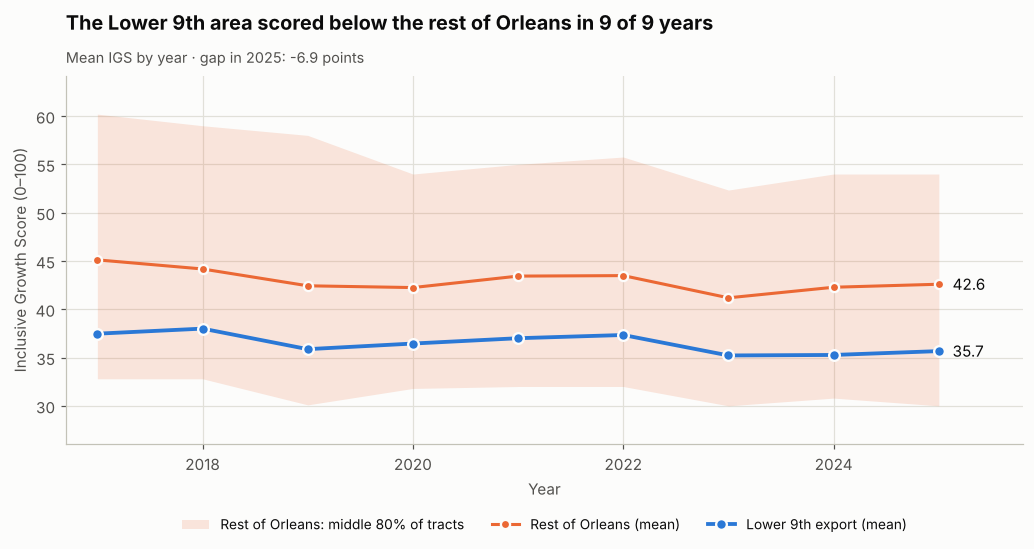

year,2017,2018,2019,2020,2021,2022,2023,2024,2025
area_group,,,,,,,,,
Lower 9th export,37.5,38.0,35.9,36.4,37.0,37.3,35.2,35.3,35.7
Rest of Orleans,45.1,44.2,42.4,42.2,43.4,43.5,41.2,42.3,42.6
gap,-7.6,-6.2,-6.6,-5.8,-6.4,-6.1,-6.0,-7.0,-6.9


In [6]:
sub = no[no.area_group.isin([STUDY, REST])]
mean_by = sub.groupby(["area_group", "year"])["igs"].mean().unstack(0)
band = no[no.area_group == REST].groupby("year")["igs"].quantile([0.1, 0.9]).unstack()
gap_by_year = mean_by[STUDY] - mean_by[REST]
n_below = int((gap_by_year < 0).sum())

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.fill_between(band.index, band[0.1], band[0.9], color=ORANGE, alpha=0.16, lw=0, label="Rest of Orleans: middle 80% of tracts")
ax.plot(mean_by.index, mean_by[REST], color=ORANGE, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.5, label="Rest of Orleans (mean)")
ax.plot(mean_by.index, mean_by[STUDY], color=BLUE, lw=2.5, marker="o", ms=7, mec=SURFACE, mew=1.5, label="Lower 9th export (mean)")
for g, col in [(STUDY, BLUE), (REST, ORANGE)]:
    ax.annotate(f"{mean_by[g].iloc[-1]:.1f}", (mean_by.index[-1], mean_by[g].iloc[-1]), xytext=(9, 0), textcoords="offset points", va="center", fontsize=10, color=INK)
ax.set_xlim(mean_by.index.min() - 0.3, mean_by.index.max() + 0.8)
ax.set_ylim(max(0, min(band[0.1].min(), mean_by.min().min()) - 4), band[0.9].max() + 4)
ax.set_xlabel("Year"); ax.set_ylabel("Inclusive Growth Score (0–100)")
headline(ax, f"The Lower 9th area scored below the rest of Orleans in {n_below} of {len(gap_by_year)} years",
         f"Mean IGS by year · gap in {YEAR}: {gap_by_year[YEAR]:+.1f} points")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
plt.tight_layout(); plt.show()
display(mean_by.round(1).assign(gap=gap_by_year.round(1)).T)

### Fig 2 — Pillar scores, 2025

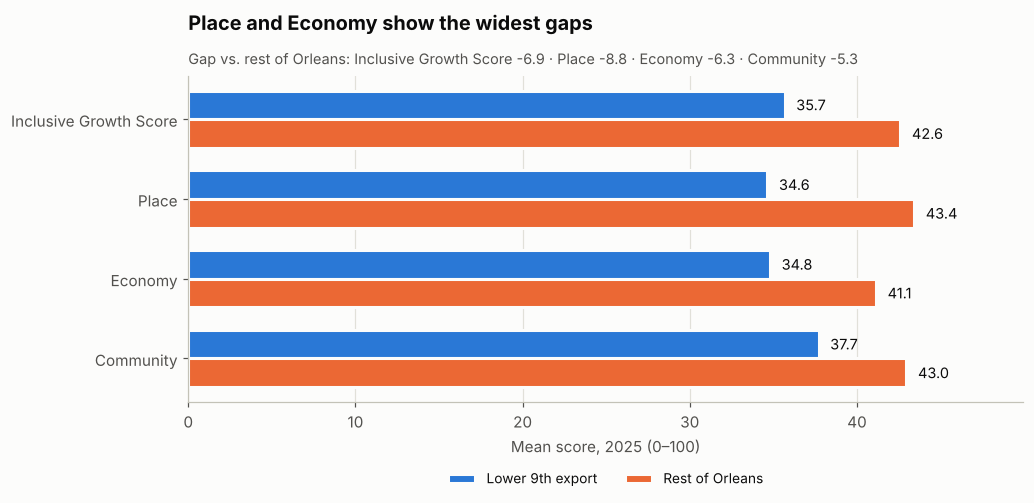

,Lower 9th export,Rest of Orleans,Gap
Inclusive Growth Score,35.7,42.6,-6.9
Place,34.6,43.4,-8.8
Economy,34.8,41.1,-6.3
Community,37.7,43.0,-5.3


In [7]:
cols = ["igs", "place", "economy", "community"]
m_s, m_r = study[cols].mean(), rest[cols].mean()
gaps = m_s - m_r
widest = gaps[PILLARS].sort_values().index[:2]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(cols))[::-1]; h = 0.36
ax.barh(y + h/2, m_s.values, h, color=BLUE, edgecolor=SURFACE, linewidth=2, label="Lower 9th export")
ax.barh(y - h/2, m_r.values, h, color=ORANGE, edgecolor=SURFACE, linewidth=2, label="Rest of Orleans")
for yy, v in zip(y + h/2, m_s.values): ax.text(v + 0.7, yy, f"{v:.1f}", va="center", fontsize=9.5)
for yy, v in zip(y - h/2, m_r.values): ax.text(v + 0.7, yy, f"{v:.1f}", va="center", fontsize=9.5)
ax.set_yticks(y); ax.set_yticklabels([LABEL[c] for c in cols]); ax.set_xlim(0, max(m_s.max(), m_r.max()) * 1.15)
ax.grid(axis="y", visible=False); ax.set_xlabel(f"Mean score, {YEAR} (0–100)")
headline(ax, f"{LABEL[widest[0]]} and {LABEL[widest[1]]} show the widest gaps",
         f"Gap vs. rest of Orleans: " + " · ".join(f"{LABEL[c]} {gaps[c]:+.1f}" for c in cols))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Lower 9th export": m_s, "Rest of Orleans": m_r, "Gap": gaps}).round(1).rename(index=LABEL))

### Fig 3 — Where the gap comes from (pillar contribution)
The overall score is the average of the three pillars (checked in section 2), so each pillar contributes **(its gap ÷ 3)** points to the overall gap. "Other / rounding" is whatever is left over.

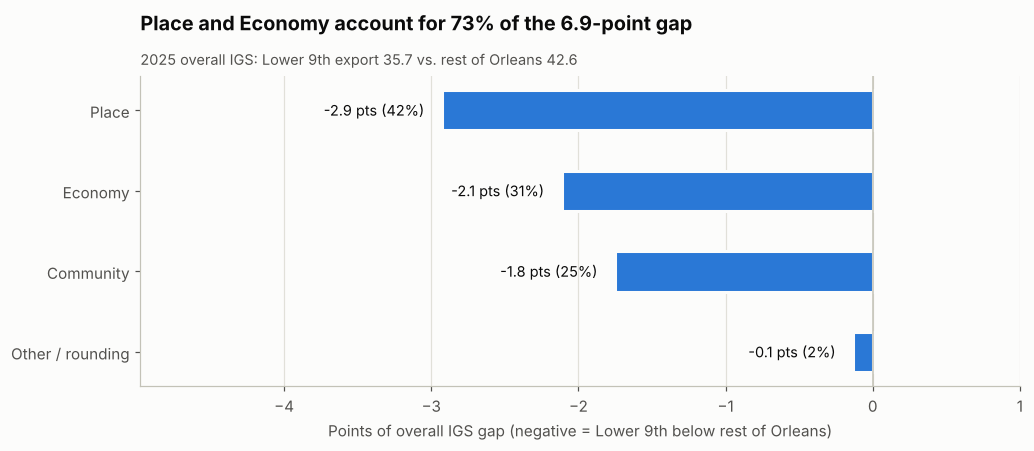

,Contribution (pts),Share of gap
Place,-2.93,42%
Economy,-2.11,31%
Community,-1.75,25%
Other / rounding,-0.13,2%


In [8]:
total_gap = m_s["igs"] - m_r["igs"]
contrib = {LABEL[p]: gaps[p] / 3 for p in PILLARS}
contrib["Other / rounding"] = total_gap - sum(contrib.values())
cs = pd.Series(contrib)
share = cs / total_gap
top2 = cs[list(LABEL[p] for p in PILLARS)].sort_values().index[:2]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
yy = np.arange(len(cs))[::-1]
ax.barh(yy, cs.values, 0.5, color=BLUE, edgecolor=SURFACE, linewidth=2)
for y_, v, s in zip(yy, cs.values, share.values):
    ax.text(v - 0.12 if v < 0 else v + 0.12, y_, f"{v:+.1f} pts ({s:.0%})", va="center", ha="right" if v < 0 else "left", fontsize=9.5)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(yy); ax.set_yticklabels(cs.index); ax.grid(axis="y", visible=False)
ax.set_xlim(min(cs.min() * 1.7, -1), max(cs.max() * 1.7, 1)); ax.set_xlabel("Points of overall IGS gap (negative = Lower 9th below rest of Orleans)")
headline(ax, f"{top2[0]} and {top2[1]} account for {share[list(top2)].sum():.0%} of the {abs(total_gap):.1f}-point gap",
         f"{YEAR} overall IGS: Lower 9th export {m_s['igs']:.1f} vs. rest of Orleans {m_r['igs']:.1f}")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Contribution (pts)": cs.round(2), "Share of gap": (share * 100).round(0).astype(int).astype(str) + "%"}))

### Fig 4 — Indicator-level gaps, 2025
Each bar is the Lower 9th export mean score minus the rest-of-Orleans mean score for one of the 18 indicators. This shows **where** the gap sits; it does not give exact points per indicator (the weights are not in the export). Acres of Park Land never changes over time in any tract, so its gap reflects a fixed feature of the area rather than a trend. Indicators with missing values are marked with the number of study tracts that have data.

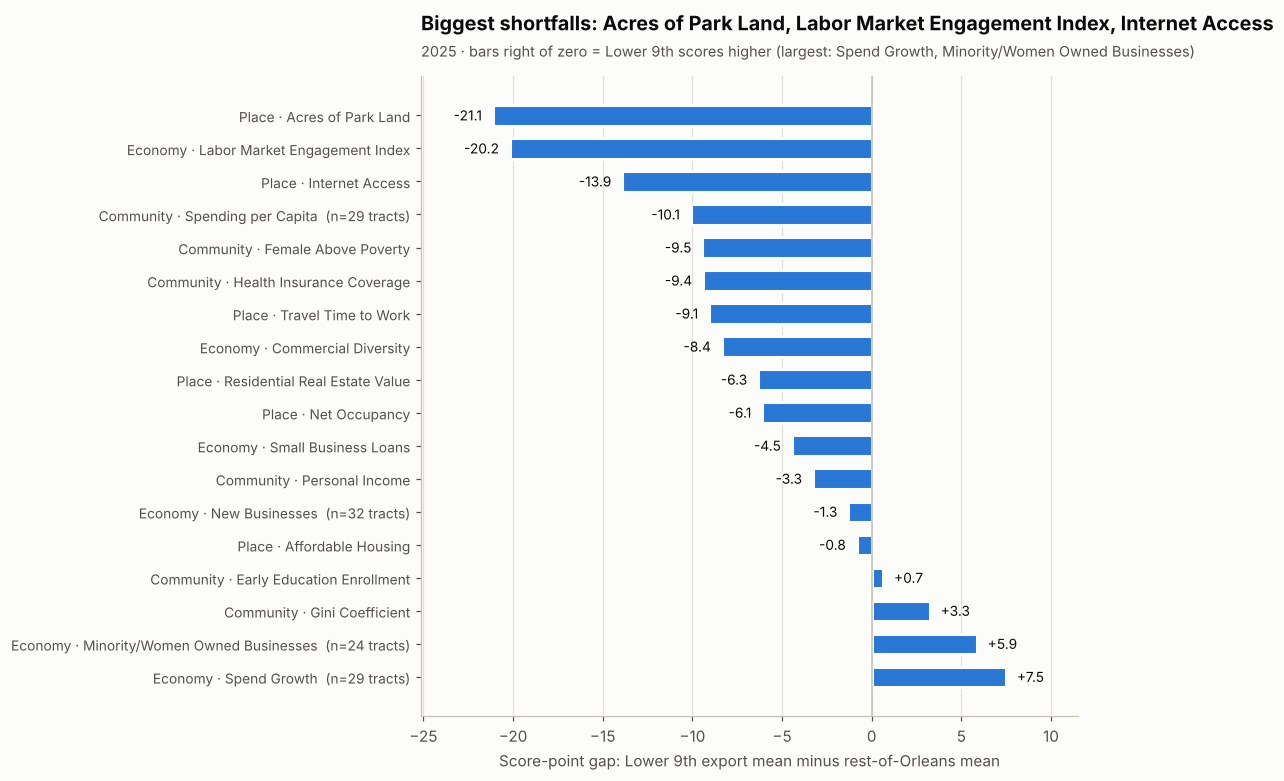

,pillar,indicator,n_study,n_rest,mean_study,mean_rest,gap
0,Place,Acres of Park Land,33,149,15.7,36.8,-21.1
1,Economy,Labor Market Engagement Index,33,148,25.7,45.9,-20.2
2,Place,Internet Access,33,148,17.4,31.3,-13.9
3,Community,Spending per Capita,29,135,39.0,49.0,-10.1
4,Community,Female Above Poverty,33,149,20.2,29.7,-9.5
5,Community,Health Insurance Coverage,33,148,32.0,41.4,-9.4
6,Place,Travel Time to Work,33,148,69.1,78.2,-9.1
7,Economy,Commercial Diversity,33,149,20.6,29.0,-8.4
8,Place,Residential Real Estate Value,33,142,36.1,42.4,-6.3
9,Place,Net Occupancy,33,149,29.3,35.4,-6.1


In [9]:
def compare(cols, s=None, r=None):
    """Study vs rest, one row per metric: means, gap, Cliff's delta, one-sided Mann-Whitney p (study < rest), Holm-adjusted p."""
    s = study if s is None else s; r = rest if r is None else r
    rows = []
    for c in cols:
        a_, b_ = s[c].dropna(), r[c].dropna()
        if len(a_) < 3 or len(b_) < 3: continue
        rows.append(dict(metric=c, n_study=len(a_), n_rest=len(b_), mean_study=a_.mean(), mean_rest=b_.mean(),
                         gap=a_.mean() - b_.mean(), median_study=a_.median(), median_rest=b_.median(),
                         cliffs_delta=cliffs_delta(a_, b_), p_one_sided=stats.mannwhitneyu(a_, b_, alternative="less").pvalue))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_one_sided"].values)
    return out

ind = compare(IND)
ind["pillar"] = ind["metric"].map(PILLAR_OF).str.title()
ind["indicator"] = ind["metric"].map(PRETTY)
ind = ind.sort_values("gap").reset_index(drop=True)
lab = [f"{r.pillar} · {r.indicator}" + (f"  (n={r.n_study} tracts)" if r.n_study < len(study) else "") for r in ind.itertuples()]

fig, ax = plt.subplots(figsize=(10, 7.2))
yy = np.arange(len(ind))[::-1]
ax.barh(yy, ind["gap"], 0.62, color=BLUE, edgecolor=SURFACE, linewidth=2)
for y_, v in zip(yy, ind["gap"]):
    ax.text(v - 0.6 if v < 0 else v + 0.6, y_, f"{v:+.1f}", va="center", ha="right" if v < 0 else "left", fontsize=9)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(yy); ax.set_yticklabels(lab, fontsize=9); ax.grid(axis="y", visible=False)
pad = max(abs(ind["gap"]).max() * 0.18, 4); ax.set_xlim(ind["gap"].min() - pad, ind["gap"].max() + pad)
ax.set_xlabel("Score-point gap: Lower 9th export mean minus rest-of-Orleans mean")
low = ind.head(3)["indicator"].tolist(); high = ind.tail(2)["indicator"].tolist()[::-1]
headline(ax, f"Biggest shortfalls: {low[0]}, {low[1]}, {low[2]}",
         f"{YEAR} · bars right of zero = Lower 9th scores higher (largest: {high[0]}, {high[1]})")
plt.tight_layout(); plt.show()
display(ind[["pillar", "indicator", "n_study", "n_rest", "mean_study", "mean_rest", "gap"]].round(1))

### Fig 5 — Growth vs. Inclusion, every Orleans tract

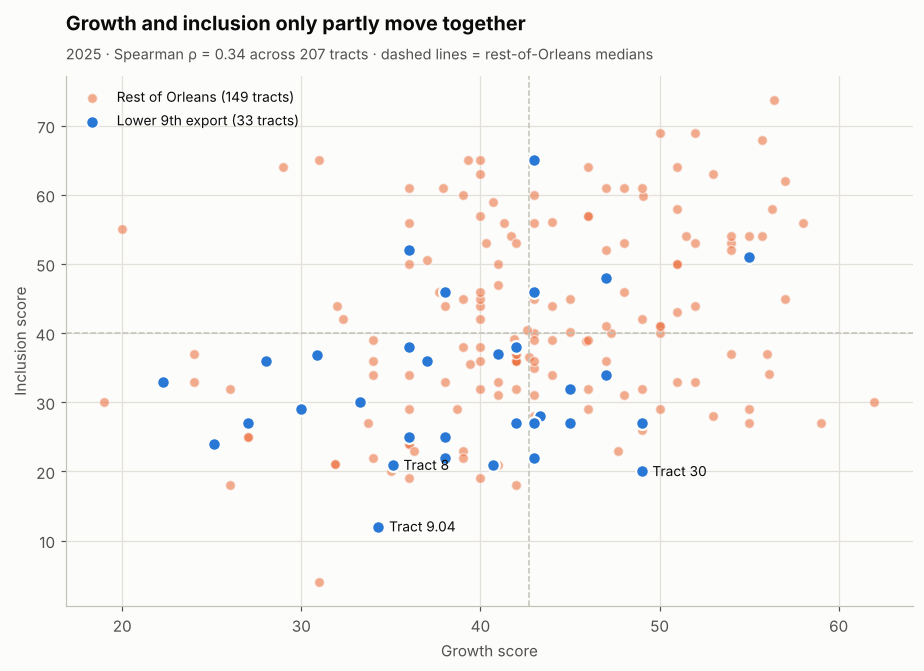

In [10]:
rho, p_rho = stats.spearmanr(cur.growth, cur.inclusion)
fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.scatter(rest.growth, rest.inclusion, s=42, color=ORANGE, alpha=0.55, edgecolor=SURFACE, linewidth=1, label=f"Rest of Orleans ({len(rest)} tracts)")
ax.scatter(study.growth, study.inclusion, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label=f"Lower 9th export ({len(study)} tracts)", zorder=3)
for r in study.nsmallest(3, "inclusion").itertuples():
    ax.annotate(f"Tract {r.tract}", (r.growth, r.inclusion), xytext=(7, -3), textcoords="offset points", fontsize=9, color=INK)
ax.axhline(rest.inclusion.median(), color=AXIS, lw=1, ls="--"); ax.axvline(rest.growth.median(), color=AXIS, lw=1, ls="--")
ax.set_xlabel("Growth score"); ax.set_ylabel("Inclusion score")
headline(ax, "Growth and inclusion only partly move together", f"{YEAR} · Spearman ρ = {rho:.2f} across {len(cur)} tracts · dashed lines = rest-of-Orleans medians")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

### Fig 6 — Inside the study area, tract by tract

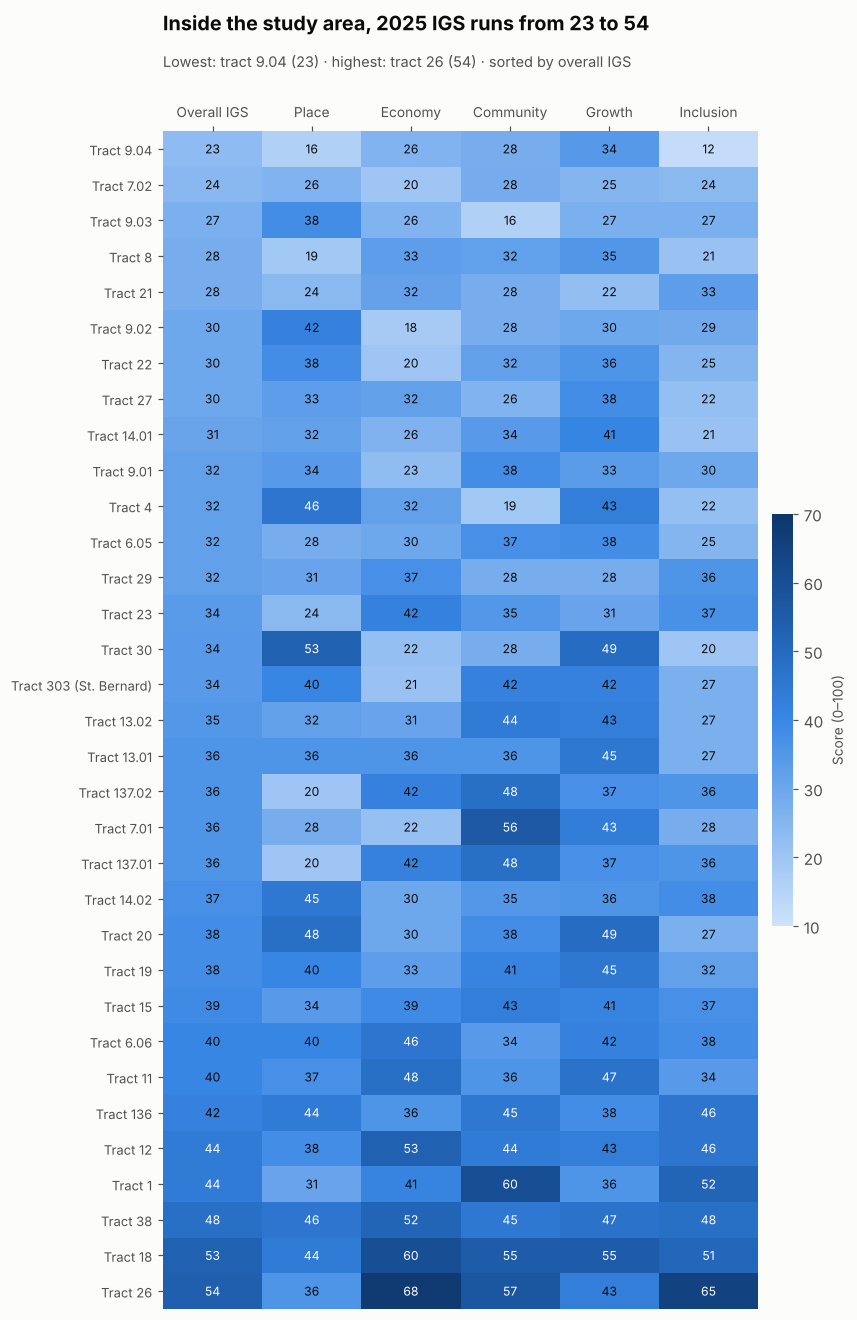

In [11]:
hm_cols = ["igs", "place", "economy", "community", "growth", "inclusion"]
hm = study.sort_values("igs")
lab = [f"Tract {r.tract}" + (f" ({r.parish})" if r.parish != "Orleans" else "") for r in hm.itertuples()]
vals = hm[hm_cols].to_numpy(float)

fig, ax = plt.subplots(figsize=(8.2, 0.3 * len(hm) + 2.2))
im = ax.imshow(vals, cmap=SEQ, vmin=10, vmax=70, aspect="auto")
ax.set_xticks(range(len(hm_cols))); ax.set_xticklabels([LABEL[c] if c != "igs" else "Overall IGS" for c in hm_cols], fontsize=9)
ax.xaxis.tick_top(); ax.set_yticks(range(len(hm))); ax.set_yticklabels(lab, fontsize=8.5)
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if (v - 10) / 60 > 0.55 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.35, pad=0.02); cb.set_label("Score (0–100)", fontsize=9); cb.outline.set_visible(False)
lo, hi = hm.iloc[0], hm.iloc[-1]
ax.set_title(f"Inside the study area, {YEAR} IGS runs from {lo.igs:.0f} to {hi.igs:.0f}", loc="left", pad=66)
ax.annotate(f"Lowest: tract {lo.tract} ({lo.igs:.0f}) · highest: tract {hi.tract} ({hi.igs:.0f}) · sorted by overall IGS", xy=(0, 1), xycoords="axes fraction", xytext=(0, 42), textcoords="offset points", fontsize=9.5, color=INK2)
plt.tight_layout(); plt.show()

## 5. Statistical tests  *(Lead Analyst)*
With 33 study tracts, tests are run on **tracts** (one 2025 value each) rather than tract-years, because the same tract's years aren't independent. Group comparisons use the Mann-Whitney U test (one-sided: study area lower), because tract scores are bounded and not normally distributed. Effect sizes (Cliff's δ) and bootstrap intervals are reported next to p-values. Tracts are not a random sample of anything, so treat p-values as a measure of how unusual the gap is, not as a population claim.

In [12]:
# ---- H1 (primary): overall IGS, 2025 ----
a_, b_ = study["igs"], rest["igs"]
u, p1 = stats.mannwhitneyu(a_, b_, alternative="less")
ci_mean = boot_ci(a_, b_, np.mean); ci_med = boot_ci(a_, b_, np.median)
print("H1  Lower 9th export tracts have lower overall IGS than the rest of Orleans (2025)")
print(f"    n = {len(a_)} vs {len(b_)} | mean {a_.mean():.1f} vs {b_.mean():.1f} (diff {a_.mean()-b_.mean():+.1f}, 95% CI {ci_mean[0]:+.1f} to {ci_mean[1]:+.1f})")
print(f"    median {a_.median():.1f} vs {b_.median():.1f} (diff {a_.median()-b_.median():+.1f}, 95% CI {ci_med[0]:+.1f} to {ci_med[1]:+.1f})")
print(f"    Mann-Whitney U = {u:.0f}, one-sided p = {p1:.2g} | Cliff's delta = {cliffs_delta(a_, b_):+.2f}")

# ---- robustness: tract-average over all nine years ----
tm = sub.groupby(["fips", "area_group"])["igs"].mean().reset_index()
ta, tb = tm[tm.area_group == STUDY]["igs"], tm[tm.area_group == REST]["igs"]
p1b = stats.mannwhitneyu(ta, tb, alternative="less").pvalue
print(f"\n    Robustness, tract means over 2017-2025: {ta.mean():.1f} vs {tb.mean():.1f}, one-sided p = {p1b:.2g}, Cliff's delta = {cliffs_delta(ta, tb):+.2f}")

# ---- H2: which pillar differs most? (family of 5 tests, Holm-adjusted) ----
fam = compare(["place", "economy", "community", "growth", "inclusion"])
fam["metric"] = fam["metric"].map(LABEL)
print("\nH2  Pillar / sub-score comparisons (Holm-adjusted across these five tests)")
display(fam[["metric", "mean_study", "mean_rest", "gap", "cliffs_delta", "p_one_sided", "p_holm"]].round(4).rename(columns={"metric": "score"}))

# ---- H3: indicator-level effect sizes ----
ind_t = ind[["pillar", "indicator", "n_study", "gap", "cliffs_delta", "p_one_sided", "p_holm"]].copy()
print("H3  Indicator comparisons ranked by effect size (Holm-adjusted across all indicators tested)")
display(ind_t.sort_values("cliffs_delta").round(3).head(10))

# ---- H4: Growth vs. Inclusion ----
rho_s, p_s = stats.spearmanr(study.growth, study.inclusion); rho_r, p_r = stats.spearmanr(rest.growth, rest.inclusion)
print(f"\nH4  Growth-Inclusion correlation (Spearman, {YEAR}): all {len(cur)} tracts rho = {rho:.2f} | study area rho = {rho_s:.2f} (p = {p_s:.2g}) | rest of Orleans rho = {rho_r:.2f} (p = {p_r:.2g})")

H1  Lower 9th export tracts have lower overall IGS than the rest of Orleans (2025)
    n = 33 vs 149 | mean 35.7 vs 42.6 (diff -6.9, 95% CI -9.7 to -4.1)
    median 35.0 vs 42.0 (diff -7.0, 95% CI -10.1 to -4.8)
    Mann-Whitney U = 1297, one-sided p = 1.1e-05 | Cliff's delta = -0.47

    Robustness, tract means over 2017-2025: 36.5 vs 43.0, one-sided p = 8.3e-06, Cliff's delta = -0.48

H2  Pillar / sub-score comparisons (Holm-adjusted across these five tests)


,score,mean_study,mean_rest,gap,cliffs_delta,p_one_sided,p_holm
0,Place,34.6364,43.4188,-8.7824,-0.4397,0.0000,0.0002
1,Economy,34.7970,41.1362,-6.3393,-0.3014,0.0034,0.0102
2,Community,37.7000,42.9517,-5.2517,-0.2809,0.0058,0.0102
3,Growth,38.7879,43.1544,-4.3665,-0.3006,0.0035,0.0102
4,Inclusion,32.6909,41.9691,-9.2782,-0.4090,0.0001,0.0005


H3  Indicator comparisons ranked by effect size (Holm-adjusted across all indicators tested)


,pillar,indicator,n_study,gap,cliffs_delta,p_one_sided,p_holm
0,Place,Acres of Park Land,33,-21.135,-0.477,0.000,0.000
10,Economy,Small Business Loans,33,-4.464,-0.386,0.000,0.005
1,Economy,Labor Market Engagement Index,33,-20.186,-0.346,0.001,0.015
2,Place,Internet Access,33,-13.919,-0.284,0.005,0.081
3,Community,Spending per Capita,29,-10.093,-0.273,0.011,0.148
9,Place,Net Occupancy,33,-6.110,-0.233,0.018,0.238
6,Place,Travel Time to Work,33,-9.073,-0.222,0.023,0.279
7,Economy,Commercial Diversity,33,-8.370,-0.218,0.025,0.279
5,Community,Health Insurance Coverage,33,-9.412,-0.212,0.029,0.286
4,Community,Female Above Poverty,33,-9.452,-0.192,0.042,0.380



H4  Growth-Inclusion correlation (Spearman, 2025): all 207 tracts rho = 0.34 | study area rho = 0.12 (p = 0.51) | rest of Orleans rho = 0.28 (p = 0.00057)


### Fig 7 — Distribution behind the headline test

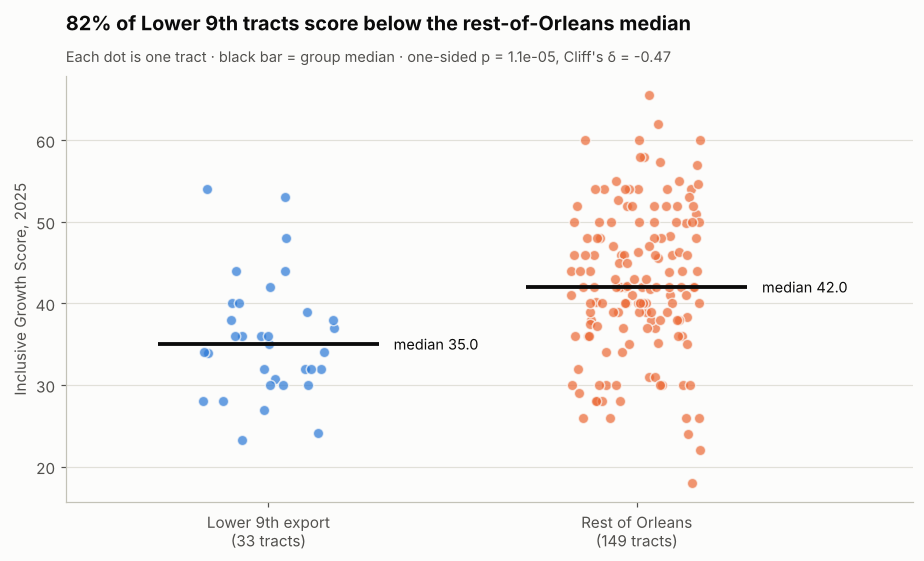

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
rng = np.random.default_rng(7)
for x0, d, col, name in [(0, study, BLUE, STUDY), (1, rest, ORANGE, REST)]:
    jit = rng.uniform(-0.18, 0.18, len(d))
    ax.scatter(x0 + jit, d["igs"], s=46, color=col, alpha=0.7, edgecolor=SURFACE, linewidth=1)
    med = d["igs"].median()
    ax.hlines(med, x0 - 0.3, x0 + 0.3, color=INK, lw=2.5)
    ax.text(x0 + 0.34, med, f"median {med:.1f}", va="center", fontsize=9.5)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"{STUDY}\n({len(study)} tracts)", f"{REST}\n({len(rest)} tracts)"])
ax.set_xlim(-0.55, 1.75); ax.grid(axis="x", visible=False); ax.set_ylabel(f"Inclusive Growth Score, {YEAR}")
below = (study["igs"] < rest["igs"].median()).mean()
headline(ax, f"{below:.0%} of Lower 9th tracts score below the rest-of-Orleans median", f"Each dot is one tract · black bar = group median · one-sided p = {p1:.2g}, Cliff's δ = {cliffs_delta(a_, b_):+.2f}")
plt.tight_layout(); plt.show()

## 6. Findings  *(numbers below are computed from the data above, so they update if the inputs change)*

In [14]:
worst = ind.head(3); best = ind.tail(2)
print(f"1. Gap size. In {YEAR} the Lower 9th export averages {m_s['igs']:.1f} on the IGS vs {m_r['igs']:.1f} for the rest of Orleans ({total_gap:+.1f} points). It trailed in {n_below} of {len(gap_by_year)} years since 2017.")
print(f"2. Pillars. Gap vs. rest of Orleans: Place {gaps['place']:+.1f}, Economy {gaps['economy']:+.1f}, Community {gaps['community']:+.1f}. {top2[0]} and {top2[1]} together account for {share[list(top2)].sum():.0%} of the overall IGS gap.")
print(f"3. Indicators. Largest shortfalls: " + "; ".join(f"{r.pillar} · {r.indicator} ({r.gap:+.1f})" for r in worst.itertuples()) + ".")
print(f"   Largest advantages for the study area: " + "; ".join(f"{r.pillar} · {r.indicator} ({r.gap:+.1f}, based on {r.n_study} of {len(study)} study tracts)" for r in best.iloc[::-1].itertuples()) + ".")
print(f"4. Strength of evidence. Overall IGS: one-sided p = {p1:.2g}, Cliff's delta = {cliffs_delta(a_, b_):+.2f}; the same direction holds for tract averages over all years (p = {p1b:.2g}).")
print(f"5. Spread inside the area. Tract IGS runs from {study.igs.min():.0f} to {study.igs.max():.0f}; the lowest is tract {study.loc[study.igs.idxmin(), 'tract']}. A single neighborhood average hides this range.")
print(f"6. Definition matters. Gap vs. rest of Orleans: " + "; ".join(f"{k.split(' (')[0]}: {v[LABEL['igs']] - m_r['igs']:+.1f}" for k, v in sens_tbl.iloc[:3].iterrows()) + ".")
print("\nCaution: these are associations in tract-level scores. The export contains no data on causes (flooding, disinvestment, population change), and indicator weights are not published in it.")

1. Gap size. In 2025 the Lower 9th export averages 35.7 on the IGS vs 42.6 for the rest of Orleans (-6.9 points). It trailed in 9 of 9 years since 2017.
2. Pillars. Gap vs. rest of Orleans: Place -8.8, Economy -6.3, Community -5.3. Place and Economy together account for 73% of the overall IGS gap.
3. Indicators. Largest shortfalls: Place · Acres of Park Land (-21.1); Economy · Labor Market Engagement Index (-20.2); Place · Internet Access (-13.9).
   Largest advantages for the study area: Economy · Spend Growth (+7.5, based on 29 of 33 study tracts); Economy · Minority/Women Owned Businesses (+5.9, based on 24 of 33 study tracts).
4. Strength of evidence. Overall IGS: one-sided p = 1.1e-05, Cliff's delta = -0.47; the same direction holds for tract averages over all years (p = 8.3e-06).
5. Spread inside the area. Tract IGS runs from 23 to 54; the lowest is tract 9.04. A single neighborhood average hides this range.
6. Definition matters. Gap vs. rest of Orleans: Study area: -6.9; Study 

## 7. Phase III handoff  *(Machine Learning Engineer)*
- **Modeling frame:** `clean_data/igs_new_orleans_clean.csv` (all scored tracts, 2017–2025). Use all tracts for training; the study area is the case study, not the training set.
- **Validation:** `GroupKFold` grouped by `fips`, so no tract's years appear in both train and test.
- **Leakage:** pillar scores are built from the indicator scores and the IGS is the average of the pillars. Don't predict a pillar from its own indicators, and don't include `igs`, `growth` or `inclusion` as features when the target is derived from them.
- **Features to drop:** every `*_base_*` column (one value per year for all tracts, so no tract-level signal) and `acres_of_park_land_*` (never changes).
- **Missing data:** impute inside each CV fold and keep a missing-indicator flag for the columns in the audit table (minority/women-owned businesses, spending, real estate value).
- **Candidate targets:** (a) regress `inclusion` or `igs` on the tract-level indicator values; (b) classify tracts in the bottom quartile of IGS. Compare a regularized linear model with a tree ensemble, and report permutation importance by pillar.
- **Narrative link:** the interventions in the final briefing should target the indicators with the largest gaps in Fig 4 that also rank high in model importance.

---
# Part 2 — Phase III: Forecasting model
The cells below start from the cleaned CSV written by Part 1 (`clean_data/igs_new_orleans_clean.csv`), so run Part 1 first. Part 3 follows at the end.

# Phase III: Forecasting Inclusive Growth — Lower Ninth Ward vs. New Orleans
**Machine Learning Engineer notebook** · input: `igs_new_orleans_clean.csv` from the Phase II notebook

**What the models predict:** a tract's Inclusive Growth Score (IGS) **next year**, using this year's 18 indicator scores. This is a genuine forecasting task, not a re-computation of the score, because the target year's values are never seen.

**How this connects to the research question** (*How does the Lower Ninth Ward compare to the rest of Orleans Parish, and which factors drive the gap?*):
- Does the gap persist? The models forecast the next year for both groups.
- Do the models serve the Lower Ninth as well as the rest of the city? (error and bias by group)
- Which indicators carry the predictive signal? (permutation importance)

**Notebook map:** 1 Build the forecasting panel → 2 Baselines & models → 3 Validation design → 4 Results → 5 Fairness check by group → 6 What drives the predictions → 7 Forecast & tie-back → 8 Findings & limits

In [15]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold

# ---- palette: same as Phase II. Blue = Lower 9th export, orange = rest of Orleans, aqua = outside Orleans / models
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
INK, INK2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

STUDY, REST, OUTSIDE = "Lower 9th export", "Rest of Orleans", "Outside Orleans"
GROUP_COLOR = {STUDY: BLUE, REST: ORANGE, OUTSIDE: AQUA}
FIRST_TEST_TARGET_YEAR = 2023          # models train on targets up to 2022 and are tested on 2023-2025
SEED = 42
OUT_DIR = Path("clean_data"); OUT_DIR.mkdir(exist_ok=True)

def headline(ax, text, sub=None):
    ax.set_title(text, loc="left", pad=30 if sub else 12)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.5, color=INK2)

## 1. Build the forecasting panel
Each row is one tract in one year *t*: the **features** are that year's indicator scores, and the **target** is the same tract's IGS in year *t+1*. With 2017–2025 data that gives eight transitions per tract (2017→2018 … 2024→2025).

**Leakage rules applied here:**
- Only the 18 indicator scores are used as inputs. The pillar scores, Growth and Inclusion are *not* used, because they are built from the same indicators as the IGS.
- The benchmark ("Base") columns are not used: they hold one value per year for every tract, so they carry no tract-level signal.
- Nothing from year *t+1* or later enters the features.

In [16]:
CSV = "igs_new_orleans_clean.csv"
cands = [Path(CSV), Path("clean_data") / CSV, Path("data") / CSV, Path("/content") / CSV, Path("/content/clean_data") / CSV]
path = next((p for p in cands if p.exists()), None)
if path is None:
    try:
        from google.colab import files
        print("Upload igs_new_orleans_clean.csv (it is written by the Phase II notebook).")
        path = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(f"Could not find {CSV}. Run the Phase II notebook first, or put the file next to this one.")
df = pd.read_csv(path, dtype={"fips": str})
print("Loaded", path, "->", df.shape, "| tracts:", df.fips.nunique(), "| years:", df.year.min(), "-", df.year.max())

PILLAR_OF = {
    "net_occupancy_score": "Place", "residential_real_estate_value_score": "Place", "acres_of_park_land_score": "Place",
    "affordable_housing_score": "Place", "internet_access_score": "Place", "travel_time_to_work_score": "Place",
    "new_businesses_score": "Economy", "spend_growth_score": "Economy", "small_business_loans_score": "Economy",
    "minority_women_owned_businesses_score": "Economy", "labor_market_engagement_index_score": "Economy", "commercial_diversity_score": "Economy",
    "personal_income_score": "Community", "spending_per_capita_score": "Community", "female_above_poverty_score": "Community",
    "gini_coefficient_score": "Community", "early_education_enrollment_score": "Community", "health_insurance_coverage_score": "Community",
}
IND = [c for c in df.columns if c.endswith("_score")]
assert set(IND) == set(PILLAR_OF), "indicator columns changed - update PILLAR_OF"
def pretty(c):
    s = c[:-len("_score")].replace("_", " ").title()
    return s.replace("Minority Women", "Minority/Women").replace("Spending Per", "Spending per")

nxt = df[["fips", "year", "igs"]].assign(year=lambda d: d.year - 1).rename(columns={"igs": "igs_next"})
panel = df.rename(columns={"igs": "igs_now"}).merge(nxt, on=["fips", "year"], how="inner")
panel["target_year"] = panel["year"] + 1
panel = panel[["fips", "tract", "parish", "area_group", "year", "target_year", "igs_now", "igs_next"] + IND].reset_index(drop=True)

train_all = panel[panel.target_year < FIRST_TEST_TARGET_YEAR].reset_index(drop=True)
test_all = panel[panel.target_year >= FIRST_TEST_TARGET_YEAR].reset_index(drop=True)
print(f"Panel: {len(panel)} tract-year transitions | training years (targets <= {FIRST_TEST_TARGET_YEAR-1}): {len(train_all)} | test years (targets {FIRST_TEST_TARGET_YEAR}-2025): {len(test_all)}")
display(panel.groupby("area_group").agg(tracts=("fips", "nunique"), rows=("fips", "size")))
print(f"Indicator cells missing in the panel: {panel[IND].isna().mean().mean():.1%} (handled inside each model, never imputed in the data itself)")
print(f"Correlation between this year's and next year's IGS: {panel.igs_now.corr(panel.igs_next):.3f}  -> scores change slowly, so 'no change' will be a hard baseline.")

Loaded clean_data/igs_new_orleans_clean.csv -> (1863, 71) | tracts: 207 | years: 2017 - 2025
Panel: 1656 tract-year transitions | training years (targets <= 2022): 1035 | test years (targets 2023-2025): 621


,tracts,rows
area_group,,
Lower 9th export,33,264
Outside Orleans,25,200
Rest of Orleans,149,1192


Indicator cells missing in the panel: 3.0% (handled inside each model, never imputed in the data itself)
Correlation between this year's and next year's IGS: 0.885  -> scores change slowly, so 'no change' will be a hard baseline.


## 2. Baselines and models
Two baselines set the bar, and four models try to beat it.

| Name | What it does |
|---|---|
| **Persistence** (baseline) | Predicts next year's IGS = this year's IGS. If a model can't beat this, the indicators add nothing beyond "scores change slowly". |
| **Training mean** (baseline) | Predicts the average IGS from the training years for everyone. |
| **Ridge · indicators** | Regularized linear regression on the 18 indicator scores. Easy to interpret. |
| **Gradient boosting · indicators** | Tree ensemble on the same inputs. Can capture non-linear effects and handles missing values natively. |
| **… + current IGS** | The same two models, also given this year's IGS. This tests whether the indicators add information *on top of* persistence. |

Missing indicator values are imputed (median) **inside** each model's training step for Ridge, with a missing-value flag added, so test data never influences the imputation. Hyperparameters are fixed or tuned only on training data.

In [17]:
BASELINES = ["Persistence (next = current IGS)", "Training mean"]

def make_ridge():
    pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("sc", StandardScaler()), ("m", Ridge())])
    return GridSearchCV(pipe, {"m__alpha": [1, 10, 30, 100, 300, 1000]}, cv=GroupKFold(n_splits=3),
                        scoring="neg_mean_absolute_error")

def make_gbm():
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=250, min_samples_leaf=20,
                                         l2_regularization=1.0, random_state=SEED)

F_IND, F_IND_NOW = IND, IND + ["igs_now"]
CANDIDATES = {
    "Ridge · indicators": (make_ridge, F_IND),
    "Gradient boosting · indicators": (make_gbm, F_IND),
    "Ridge · indicators + current IGS": (make_ridge, F_IND_NOW),
    "Gradient boosting · indicators + current IGS": (make_gbm, F_IND_NOW),
}

def fit_predict(name, train, test):
    make, feats = CANDIDATES[name]
    m = make()
    if isinstance(m, GridSearchCV):
        m.fit(train[feats], train["igs_next"], groups=train["fips"])      # alpha is tuned with tract-grouped folds
    else:
        m.fit(train[feats], train["igs_next"])
    return m, m.predict(test[feats])

def baseline_predict(name, train, test):
    if name.startswith("Persistence"):
        return test["igs_now"].to_numpy(float)
    return np.full(len(test), train["igs_next"].mean())

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); e = p - y
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "R2": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2), "bias": e.mean()}

print("Defined", len(CANDIDATES), "models and", len(BASELINES), "baselines.")

Defined 4 models and 2 baselines.


## 3. Validation design
Random train/test splits would be misleading here: a tract's neighboring years look almost identical, so the model could just memorize tracts. Three checks instead:

| Check | Train on | Test on | Question it answers |
|---|---|---|---|
| **Model selection** | Targets ≤ 2022, 5 folds grouped by tract | held-out tracts, same years | Which of the four models to treat as primary (chosen *before* looking at the test years) |
| **Future years** | All tracts, targets ≤ 2022 | All tracts, targets 2023–2025 | Can we forecast the future for tracts we have seen? |
| **Future years + unseen tracts** (strictest) | Other tracts, targets ≤ 2022 | Held-out tracts, targets 2023–2025 (5 folds) | Does it work for a tract the model has never seen? |

Metrics: **MAE** (average miss, in IGS points), RMSE, R², and **bias** (average predicted minus actual; negative = under-predicts).

In [18]:
# ---------- model selection: tract-grouped CV inside the training years only ----------
gkf = GroupKFold(n_splits=5)
sel = {}
for name in CANDIDATES:
    oof = np.zeros(len(train_all))
    for tr, va in gkf.split(train_all, groups=train_all["fips"]):
        _, p = fit_predict(name, train_all.iloc[tr], train_all.iloc[va])
        oof[va] = p
    sel[name] = metrics(train_all["igs_next"], oof)["MAE"]
sel["Persistence (next = current IGS)"] = metrics(train_all["igs_next"], train_all["igs_now"])["MAE"]
sel_tbl = pd.Series(sel, name="CV MAE (training years)").sort_values().to_frame()
PRIMARY = sel_tbl.drop(index=BASELINES[0]).index[0]
print("Model selection (tract-grouped CV on training years only):"); display(sel_tbl.round(3))
print("Primary model (lowest CV error):", PRIMARY)

# ---------- check 1: future years, same tracts ----------
preds_time, fitted_time = {}, {}
for b in BASELINES: preds_time[b] = baseline_predict(b, train_all, test_all)
for name in CANDIDATES:
    fitted_time[name], preds_time[name] = fit_predict(name, train_all, test_all)

# ---------- check 2: future years + unseen tracts ----------
tracts = np.array(sorted(panel.fips.unique()))
preds_tt = {k: np.full(len(test_all), np.nan) for k in list(preds_time)}
for tr_i, te_i in GroupKFold(n_splits=5).split(tracts, groups=tracts):
    held = set(tracts[te_i])
    tr = train_all[~train_all.fips.isin(held)]; te_mask = test_all.fips.isin(held).to_numpy()
    te = test_all[te_mask]
    for b in BASELINES: preds_tt[b][te_mask] = baseline_predict(b, tr, te)
    for name in CANDIDATES:
        _, p = fit_predict(name, tr, te); preds_tt[name][te_mask] = p
assert not any(np.isnan(v).any() for v in preds_tt.values())

y_test = test_all["igs_next"].to_numpy(float)
tbl_time = pd.DataFrame({k: metrics(y_test, v) for k, v in preds_time.items()}).T
tbl_tt = pd.DataFrame({k: metrics(y_test, v) for k, v in preds_tt.items()}).T
print("\nCheck 1 - future years, same tracts (test targets 2023-2025):"); display(tbl_time.round(3))
print("Check 2 - future years AND unseen tracts:"); display(tbl_tt.round(3))

Model selection (tract-grouped CV on training years only):


,CV MAE (training years)
Ridge · indicators + current IGS,3.378
Ridge · indicators,3.414
Gradient boosting · indicators + current IGS,3.449
Gradient boosting · indicators,3.654
Persistence (next = current IGS),3.880


Primary model (lowest CV error): Ridge · indicators + current IGS



Check 1 - future years, same tracts (test targets 2023-2025):


,MAE,RMSE,R2,bias
Persistence (next = current IGS),3.183,4.126,0.800,0.412
Training mean,7.638,9.310,-0.018,1.250
Ridge · indicators,2.932,3.671,0.842,1.421
Gradient boosting · indicators,3.294,4.151,0.798,1.377
Ridge · indicators + current IGS,2.864,3.607,0.847,1.384
Gradient boosting · indicators + current IGS,3.027,3.815,0.829,1.293


Check 2 - future years AND unseen tracts:


,MAE,RMSE,R2,bias
Persistence (next = current IGS),3.183,4.126,0.800,0.412
Training mean,7.674,9.342,-0.025,1.253
Ridge · indicators,3.053,4.202,0.793,1.515
Gradient boosting · indicators,3.511,4.456,0.767,1.336
Ridge · indicators + current IGS,2.949,3.999,0.812,1.455
Gradient boosting · indicators + current IGS,3.178,4.063,0.806,1.378


## 4. Results
### Fig 1 — Does any model beat "no change"?

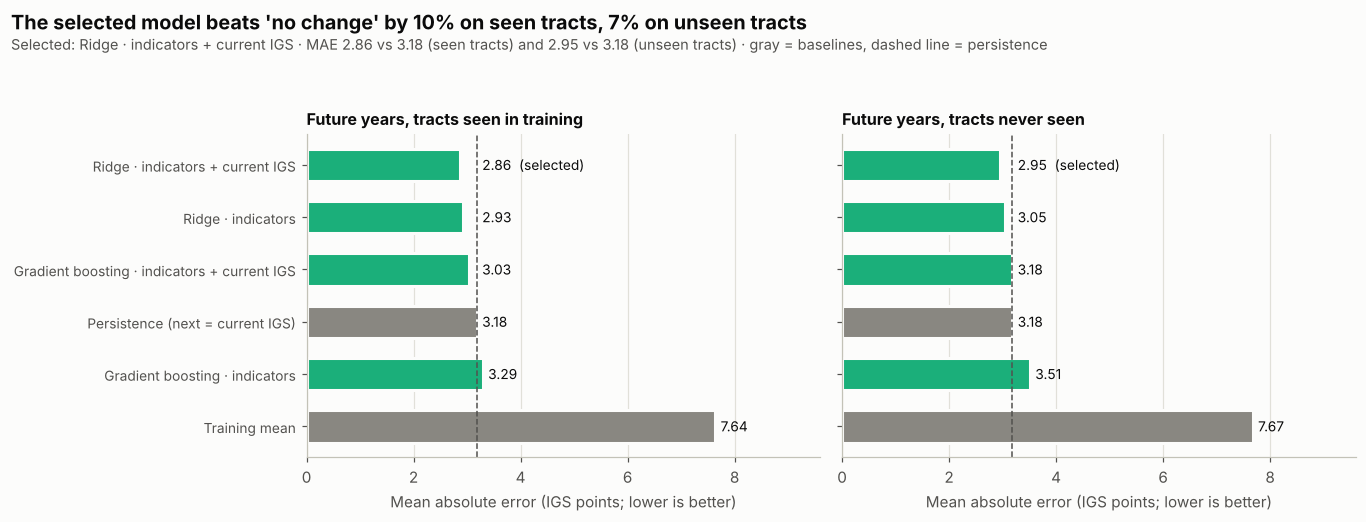

Seen tracts               Unseen tracts              
                                                     MAE   RMSE     R2           MAE   RMSE     R2
Persistence (next = current IGS)                   3.183  4.126  0.800         3.183  4.126  0.800
Training mean                                      7.638  9.310 -0.018         7.674  9.342 -0.025
Ridge · indicators                                 2.932  3.671  0.842         3.053  4.202  0.793
Gradient boosting · indicators                     3.294  4.151  0.798         3.511  4.456  0.767
Ridge · indicators + current IGS                   2.864  3.607  0.847         2.949  3.999  0.812
Gradient boosting · indicators + current IGS       3.027  3.815  0.829         3.178  4.063  0.806

In [19]:
PERS = BASELINES[0]
pm, pm_tt = tbl_time.loc[PRIMARY, "MAE"], tbl_tt.loc[PRIMARY, "MAE"]
pp, pp_tt = tbl_time.loc[PERS, "MAE"], tbl_tt.loc[PERS, "MAE"]
gain = 1 - pm / pp

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True)
for ax, tbl, ttl in [(axes[0], tbl_time, "Future years, tracts seen in training"), (axes[1], tbl_tt, "Future years, tracts never seen")]:
    t = tbl["MAE"].sort_values(ascending=False)
    cols = [MUTED if n in BASELINES else AQUA for n in t.index]
    ax.barh(range(len(t)), t.values, 0.62, color=cols, edgecolor=SURFACE, linewidth=2)
    for i, (n, v) in enumerate(t.items()):
        ax.text(max(v, tbl.loc[PERS, "MAE"]) + 0.1, i, f"{v:.2f}" + ("  (selected)" if n == PRIMARY else ""), va="center", fontsize=9)
    ax.axvline(tbl.loc[PERS, "MAE"], color=INK2, lw=1, ls="--")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=9); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 9.6)
    ax.set_title(ttl, fontsize=10.5, loc="left"); ax.set_xlabel("Mean absolute error (IGS points; lower is better)")
axes[1].set_yticklabels([])
gain_tt = 1 - pm_tt / pp_tt
if gain > 0:
    head = f"The selected model beats 'no change' by {gain:.0%} on seen tracts, {gain_tt:.0%} on unseen tracts"
else:
    head = "No model beats the 'no change' baseline on the future years"
fig.suptitle(head, x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, f"Selected: {PRIMARY} · MAE {pm:.2f} vs {pp:.2f} (seen tracts) and {pm_tt:.2f} vs {pp_tt:.2f} (unseen tracts) · gray = baselines, dashed line = persistence",
         fontsize=9.5, color=INK2)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()
display(pd.concat({"Seen tracts": tbl_time[["MAE", "RMSE", "R2"]], "Unseen tracts": tbl_tt[["MAE", "RMSE", "R2"]]}, axis=1).round(3))

In [20]:
# Is the selected model's improvement over persistence larger than chance? Bootstrap over TRACTS (years within a tract are not independent).
def tract_boot_diff(pred_a, pred_b, B=5000, seed=SEED):
    g = pd.DataFrame({"fips": test_all["fips"], "a": np.abs(pred_a - y_test), "b": np.abs(pred_b - y_test)}).groupby("fips").mean()
    d = (g["a"] - g["b"]).to_numpy(); rng = np.random.default_rng(seed)
    boots = [rng.choice(d, len(d)).mean() for _ in range(B)]
    return d.mean(), np.percentile(boots, [2.5, 97.5])

for label, preds in [("seen tracts", preds_time), ("unseen tracts", preds_tt)]:
    m, ci = tract_boot_diff(preds[PRIMARY], preds[PERS])
    verdict = "improvement is distinguishable from zero" if ci[1] < 0 else ("worse than persistence" if ci[0] > 0 else "NOT distinguishable from persistence")
    print(f"{label:<14} selected model minus persistence, MAE difference = {m:+.2f} points (95% CI {ci[0]:+.2f} to {ci[1]:+.2f}) -> {verdict}")

seen tracts    selected model minus persistence, MAE difference = -0.32 points (95% CI -0.53 to -0.11) -> improvement is distinguishable from zero
unseen tracts  selected model minus persistence, MAE difference = -0.23 points (95% CI -0.52 to +0.09) -> NOT distinguishable from persistence


### Why do the models over-predict? A citywide level shift
Bias (predicted minus actual) is positive for every model, including "no change". The table below shows the average year-over-year change in IGS: a single year can move every tract at once, and a model trained on earlier years cannot foresee that.

In [21]:
chg = panel.assign(change=panel.igs_next - panel.igs_now)
drift = chg[chg.area_group.isin([STUDY, REST])].pivot_table(index="target_year", columns="area_group", values="change", aggfunc="mean")
drift["All tracts"] = chg.groupby("target_year")["change"].mean()
drift.index.name = "target year"
display(drift.round(2))
worst = drift["All tracts"].idxmin()
print(f"Largest citywide move: {worst} ({drift.loc[worst, 'All tracts']:+.2f} points on average). Test years average {chg[chg.target_year >= FIRST_TEST_TARGET_YEAR].change.mean():+.2f}; training years average {chg[chg.target_year < FIRST_TEST_TARGET_YEAR].change.mean():+.2f}.")
print(f"Mean next-year IGS: training years {train_all.igs_next.mean():.1f} vs test years {test_all.igs_next.mean():.1f} -> models partly anchored to the earlier, higher level. This is a level shift, not a failure to rank tracts.")

area_group,Lower 9th export,Rest of Orleans,All tracts
target year,,,
2018,0.52,-0.94,-0.80
2019,-2.13,-1.74,-1.53
2020,0.58,-0.18,-0.02
2021,0.55,1.19,1.18
2022,0.33,0.05,0.04
2023,-2.12,-2.30,-2.36
2024,0.05,1.10,0.92
2025,0.40,0.31,0.20


Largest citywide move: 2023 (-2.36 points on average). Test years average -0.41; training years average -0.23.
Mean next-year IGS: training years 42.4 vs test years 41.1 -> models partly anchored to the earlier, higher level. This is a level shift, not a failure to rank tracts.


### Fig 2 — Predicted vs. actual next-year IGS (selected model, future years)

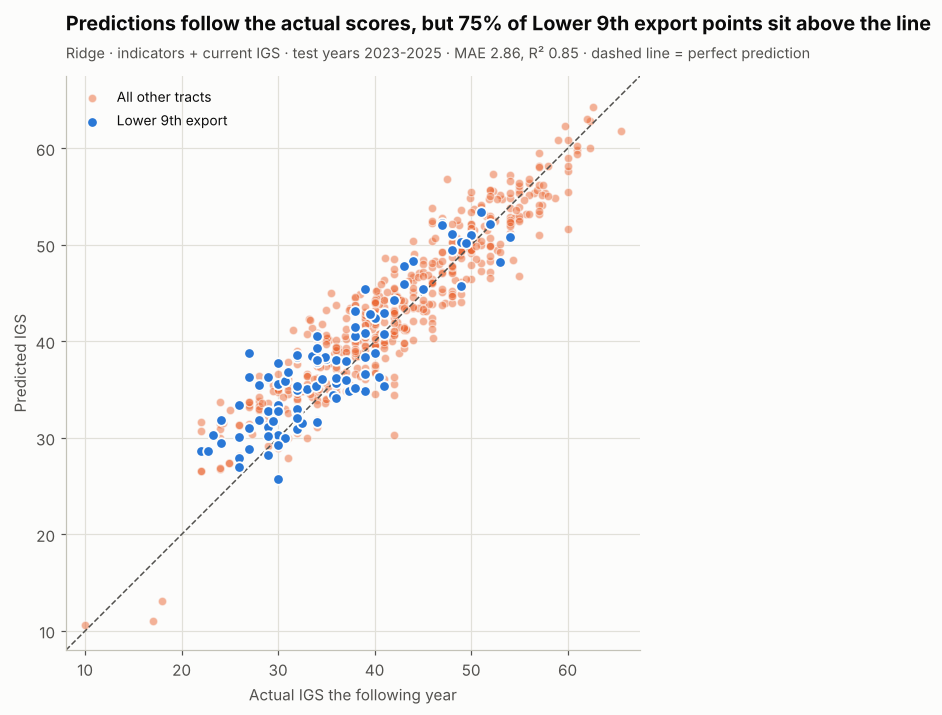

In [22]:
pred_p = preds_time[PRIMARY]
is_study = (test_all["area_group"] == STUDY).to_numpy()
fig, ax = plt.subplots(figsize=(7.4, 6.6))
ax.scatter(y_test[~is_study], pred_p[~is_study], s=30, color=ORANGE, alpha=0.5, edgecolor=SURFACE, linewidth=0.8, label="All other tracts")
ax.scatter(y_test[is_study], pred_p[is_study], s=48, color=BLUE, edgecolor=SURFACE, linewidth=1.2, label=f"{STUDY}", zorder=3)
lo, hi = min(y_test.min(), pred_p.min()) - 2, max(y_test.max(), pred_p.max()) + 2
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls="--"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("Actual IGS the following year"); ax.set_ylabel("Predicted IGS")
mm = metrics(y_test, pred_p)
share_above = float((pred_p[is_study] > y_test[is_study]).mean())
headline(ax, f"Predictions follow the actual scores, but {share_above:.0%} of Lower 9th export points sit above the line", f"{PRIMARY} · test years {FIRST_TEST_TARGET_YEAR}-2025 · MAE {mm['MAE']:.2f}, R² {mm['R2']:.2f} · dashed line = perfect prediction")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Fairness check — does the model serve the Lower Ninth as well as the rest of the metro?
A model that is accurate on average can still be systematically wrong for one community. We compare **error** (MAE) and **bias** (predicted minus actual) by group.

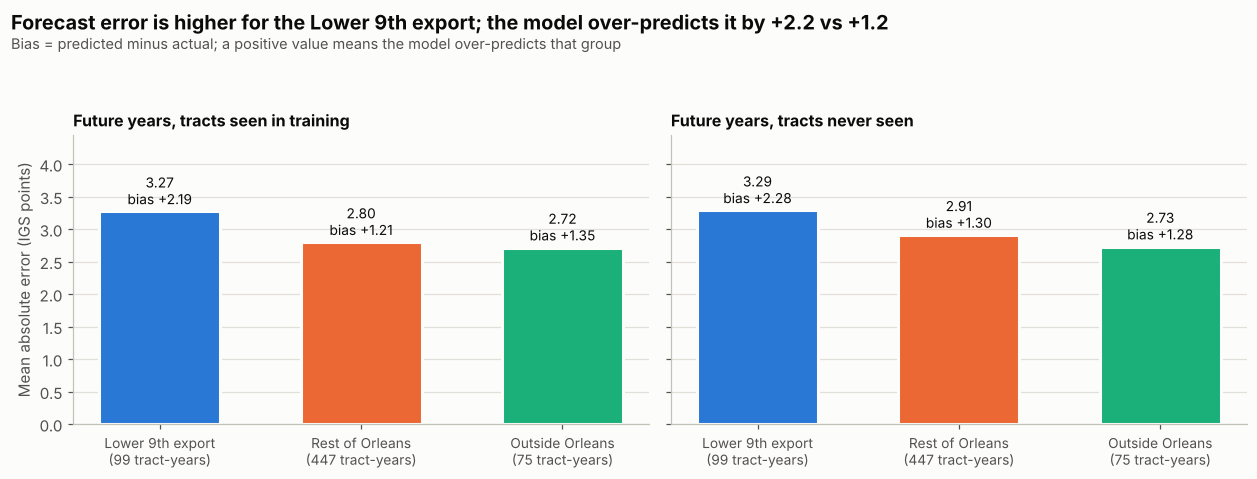

Selected, seen tracts             Selected, unseen tracts             Persistence            
                                  rows   MAE  bias                    rows   MAE  bias        rows   MAE  bias
group                                                                                                         
Lower 9th export                    99  3.27  2.19                      99  3.29  2.28          99  3.53  0.56
Rest of Orleans                    447  2.80  1.21                     447  2.91  1.30         447  3.15  0.30
Outside Orleans                     75  2.72  1.35                      75  2.73  1.28          75  2.94  0.91


2025 gap, Lower 9th export minus rest of Orleans: actual -6.92 | predicted from 2024 indicators -5.98


In [23]:
def group_table(test, pred):
    e = np.asarray(pred, float) - test["igs_next"].to_numpy(float)
    t = pd.DataFrame({"group": test["area_group"].to_numpy(), "abs_err": np.abs(e), "err": e})
    return t.groupby("group").agg(rows=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("err", "mean")).reindex([STUDY, REST, OUTSIDE])

g_time, g_tt = group_table(test_all, preds_time[PRIMARY]), group_table(test_all, preds_tt[PRIMARY])
g_pers = group_table(test_all, preds_time[PERS])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for ax, g, ttl in [(axes[0], g_time, "Future years, tracts seen in training"), (axes[1], g_tt, "Future years, tracts never seen")]:
    ax.bar(range(3), g["MAE"], 0.6, color=[GROUP_COLOR[k] for k in g.index], edgecolor=SURFACE, linewidth=2)
    for i, (k, r) in enumerate(g.iterrows()):
        ax.text(i, r["MAE"] + 0.06, f"{r['MAE']:.2f}\nbias {r['bias']:+.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{k}\n({int(g.loc[k, 'rows'])} tract-years)" for k in g.index], fontsize=9)
    ax.grid(axis="x", visible=False); ax.set_title(ttl, fontsize=10.5, loc="left"); ax.set_ylim(0, g["MAE"].max() * 1.35)
axes[0].set_ylabel("Mean absolute error (IGS points)")
diff = g_time.loc[STUDY, "MAE"] - g_time.loc[REST, "MAE"]
bdiff = g_time.loc[STUDY, "bias"] - g_time.loc[REST, "bias"]
fig.suptitle(("Forecast error is higher for the Lower 9th export" if diff > 0.25 else "Forecast error is similar for the Lower 9th export and the rest of Orleans")
             + f"; the model over-predicts it by {g_time.loc[STUDY, 'bias']:+.1f} vs {g_time.loc[REST, 'bias']:+.1f}",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.9, "Bias = predicted minus actual; a positive value means the model over-predicts that group", fontsize=9.5, color=INK2)
plt.tight_layout(rect=(0, 0, 1, 0.89)); plt.show()
display(pd.concat({"Selected, seen tracts": g_time, "Selected, unseen tracts": g_tt, "Persistence": g_pers}, axis=1).round(2))

# Does the model reproduce the 2025 gap between the Lower 9th export and the rest of Orleans?
m25 = (test_all["target_year"] == 2025).to_numpy()
t25 = test_all[m25].assign(pred=preds_time[PRIMARY][m25])
gap_act = t25[t25.area_group == STUDY].igs_next.mean() - t25[t25.area_group == REST].igs_next.mean()
gap_pred = t25[t25.area_group == STUDY].pred.mean() - t25[t25.area_group == REST].pred.mean()
print(f"\n2025 gap, Lower 9th export minus rest of Orleans: actual {gap_act:+.2f} | predicted from 2024 indicators {gap_pred:+.2f}")

## 6. What drives the predictions? *(permutation importance)*
Shuffling one indicator in the test data and measuring how much the error rises shows how much the model relies on it. This uses the **best indicator-only model** (chosen by training-period CV), so the answer isn't dominated by the current IGS; a gradient-boosting cross-check follows the figure. Higher = the model depends on it more. This is predictive importance, **not** a causal effect.

Importance computed for: Ridge · indicators (best indicator-only model by CV)


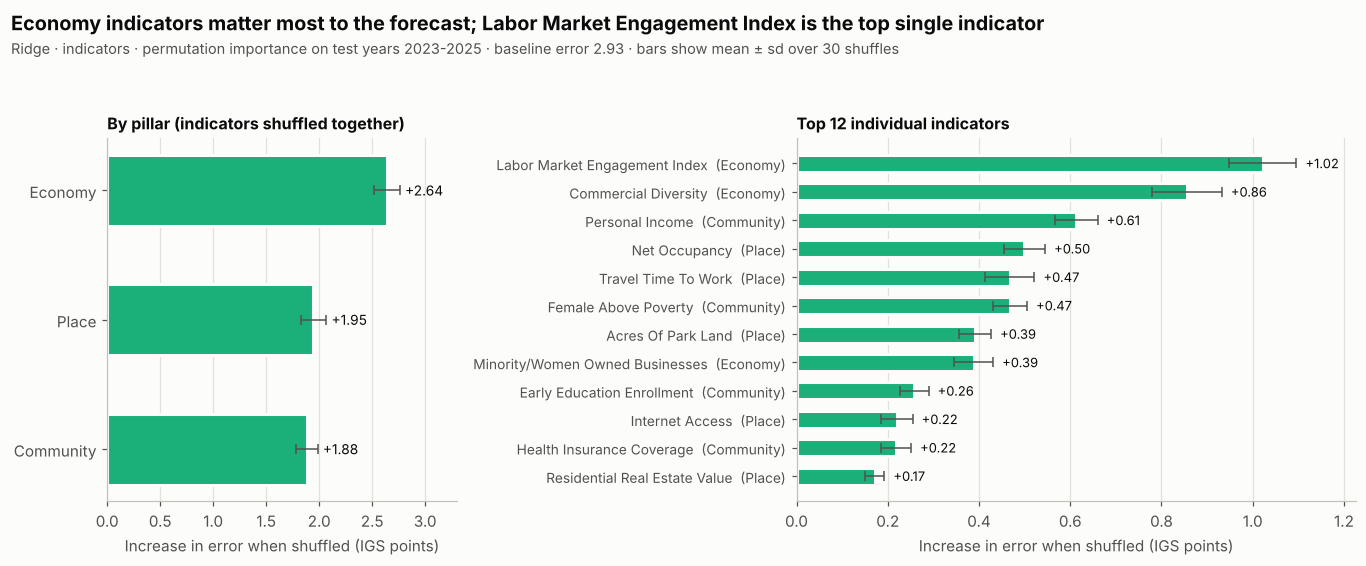

,mean,sd,pillar
Labor Market Engagement Index,1.022,0.074,Economy
Commercial Diversity,0.856,0.076,Economy
Personal Income,0.613,0.047,Community
Net Occupancy,0.499,0.045,Place
Travel Time To Work,0.467,0.054,Place
Female Above Poverty,0.467,0.038,Community
Acres Of Park Land,0.391,0.036,Place
Minority/Women Owned Businesses,0.388,0.043,Economy
Early Education Enrollment,0.258,0.031,Community
Internet Access,0.220,0.034,Place


Rank agreement between Ridge · indicators and gradient boosting importances: Spearman 0.93
Gradient boosting top 3: Labor Market Engagement Index, Commercial Diversity, Personal Income
Caveat: Acres of Park Land never changes within a tract, so models can use it as a tract fingerprint; read its importance as 'tract level', not as park change.
Ridge (alpha = 30) standardized coefficients - points of next-year IGS per 1 sd of the indicator:


,coefficient
Small Business Loans,-0.31
New Businesses,-0.03
Spending per Capita,0.00
Spend Growth,0.25
Gini Coefficient,0.43
Affordable Housing,0.71
Internet Access,0.84
Residential Real Estate Value,0.85
Early Education Enrollment,0.90
Minority/Women Owned Businesses,0.95


In [24]:
IND_ONLY = [n for n in CANDIDATES if "current IGS" not in n]
IMP_NAME = min(IND_ONLY, key=lambda n: sel[n])               # best indicator-only model by training-period CV
imp_model = fitted_time[IMP_NAME]
print("Importance computed for:", IMP_NAME, "(best indicator-only model by CV)")
X_te = test_all[F_IND].copy()
base_mae = np.mean(np.abs(imp_model.predict(X_te) - y_test))
gbm_model = fitted_time["Gradient boosting · indicators"]
def single_imp(model, reps=15):
    b = np.mean(np.abs(model.predict(X_te) - y_test)); r = np.random.default_rng(SEED + 1); o = {}
    for c in IND:
        v = []
        for _ in range(reps):
            Xp = X_te.copy(); Xp[c] = X_te[c].to_numpy()[r.permutation(len(Xp))]; v.append(np.mean(np.abs(model.predict(Xp) - y_test)) - b)
        o[pretty(c)] = np.mean(v)
    return pd.Series(o)
rng = np.random.default_rng(SEED)

def perm_importance(cols, reps=30):
    out = []
    for _ in range(reps):
        Xp = X_te.copy(); idx = rng.permutation(len(Xp))
        Xp[cols] = X_te[cols].to_numpy()[idx]                      # shuffle the columns together, rows stay aligned
        out.append(np.mean(np.abs(imp_model.predict(Xp) - y_test)) - base_mae)
    return np.mean(out), np.std(out)

ind_imp = pd.DataFrame({pretty(c): perm_importance([c]) for c in IND}, index=["mean", "sd"]).T.sort_values("mean", ascending=False)
ind_imp["pillar"] = [PILLAR_OF[c] for c in [next(k for k in IND if pretty(k) == n) for n in ind_imp.index]]
pil_imp = pd.DataFrame({p: perm_importance([c for c in IND if PILLAR_OF[c] == p]) for p in ["Place", "Economy", "Community"]}, index=["mean", "sd"]).T.sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]; yy = np.arange(len(pil_imp))[::-1]
ax.barh(yy, pil_imp["mean"], 0.55, xerr=pil_imp["sd"], color=AQUA, edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK2, "lw": 1, "capsize": 3})
for y_, v, e in zip(yy, pil_imp["mean"], pil_imp["sd"]): ax.text(v + e + 0.05, y_, f"+{v:.2f}", fontsize=9, va="center")
ax.set_xlim(0, pil_imp["mean"].max() * 1.25)
ax.set_yticks(yy); ax.set_yticklabels(pil_imp.index); ax.grid(axis="y", visible=False); ax.set_xlabel("Increase in error when shuffled (IGS points)")
ax.set_title("By pillar (indicators shuffled together)", fontsize=10.5, loc="left")
ax = axes[1]; top = ind_imp.head(12); yy = np.arange(len(top))[::-1]
ax.barh(yy, top["mean"], 0.6, xerr=top["sd"], color=AQUA, edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK2, "lw": 1, "capsize": 3})
for y_, v, e in zip(yy, top["mean"], top["sd"]): ax.text(v + e + 0.02, y_, f"+{v:.2f}", fontsize=8.5, va="center")
ax.set_xlim(0, top["mean"].max() * 1.2)
ax.set_yticks(yy); ax.set_yticklabels([f"{n}  ({p})" for n, p in zip(top.index, top["pillar"])], fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("Increase in error when shuffled (IGS points)"); ax.set_title("Top 12 individual indicators", fontsize=10.5, loc="left")
fig.suptitle(f"{pil_imp.index[0]} indicators matter most to the forecast; {ind_imp.index[0]} is the top single indicator", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, f"{IMP_NAME} · permutation importance on test years {FIRST_TEST_TARGET_YEAR}-2025 · baseline error {base_mae:.2f} · bars show mean ± sd over 30 shuffles", fontsize=9.5, color=INK2)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()
display(ind_imp.round(3))

gbm_imp = single_imp(gbm_model)
rho = ind_imp["mean"].rank().corr(gbm_imp.reindex(ind_imp.index).rank())
print(f"Rank agreement between {IMP_NAME} and gradient boosting importances: Spearman {rho:.2f}")
print("Gradient boosting top 3:", ", ".join(gbm_imp.sort_values(ascending=False).head(3).index))
print("Caveat: Acres of Park Land never changes within a tract, so models can use it as a tract fingerprint; read its importance as 'tract level', not as park change.")

# Linear view of the same inputs: standardized ridge coefficients (first 18 columns are the indicator scores)
rm = fitted_time["Ridge · indicators"].best_estimator_
coef = pd.Series(rm.named_steps["m"].coef_[:len(IND)], index=[pretty(c) for c in IND]).sort_values()
print(f"Ridge (alpha = {fitted_time['Ridge · indicators'].best_params_['m__alpha']}) standardized coefficients - points of next-year IGS per 1 sd of the indicator:")
display(coef.round(2).to_frame("coefficient"))

## 7. Forecast and tie-back to the comparison
The selected model is refit on **all** available transitions and applied to the 2025 indicators to project 2026. The whiskers show the model's typical miss (its future-years MAE), so read each bar as a rough range, not a precise number.

,igs_2025,pred_2026,change
area_group,,,
Lower 9th export,35.67,36.53,0.86
Rest of Orleans,42.59,42.54,-0.05
Outside Orleans,43.34,43.24,-0.10


Gap (Lower 9th export minus rest of Orleans): 2025 actual -6.92 -> 2026 forecast -6.01


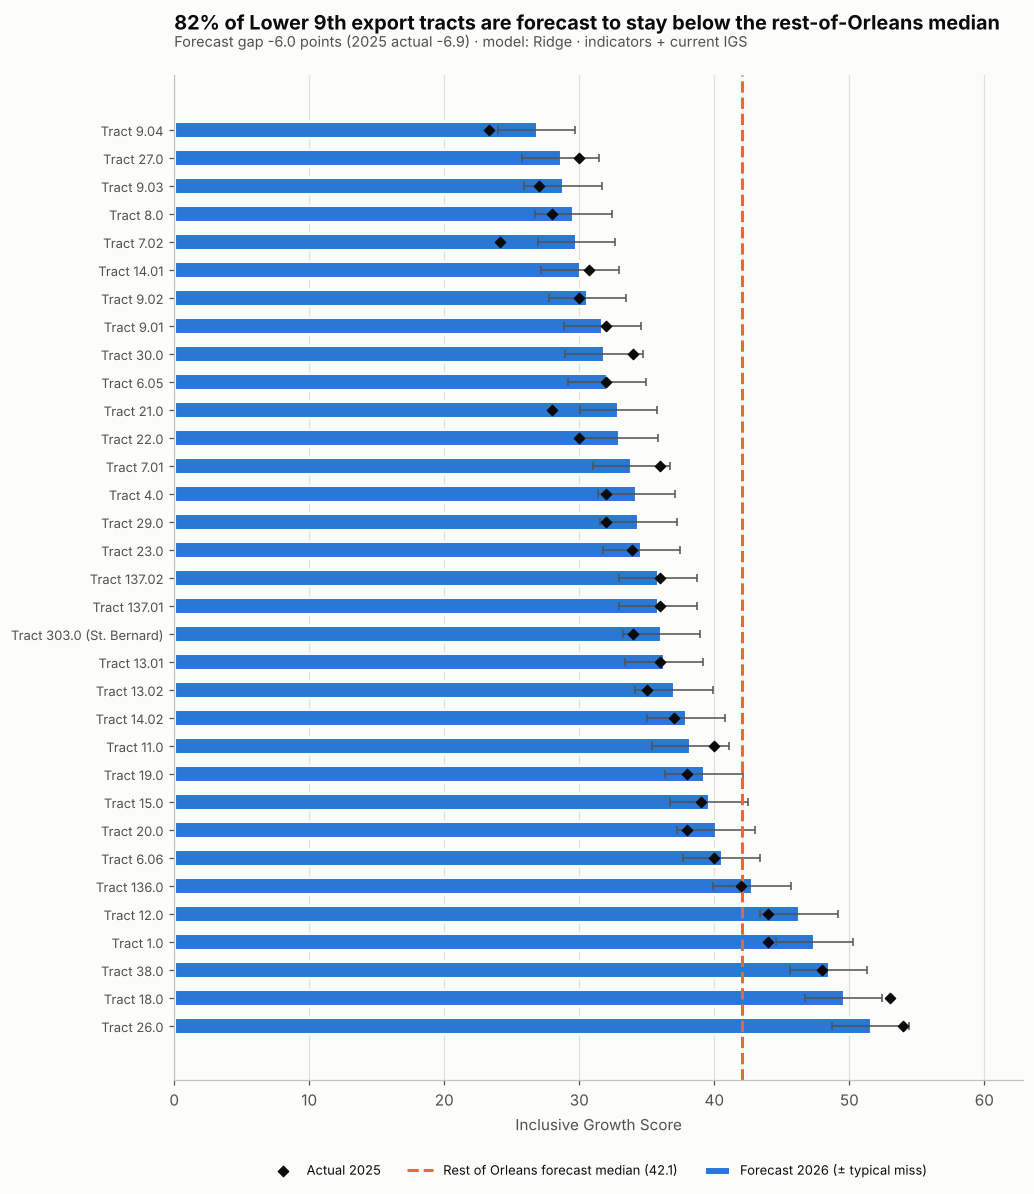

,tract,parish,igs_2025,pred_2026
0,9.04,Orleans,23.3,26.9
1,27.00,Orleans,30.0,28.6
2,9.03,Orleans,27.0,28.8
3,8.00,Orleans,28.0,29.6
4,7.02,Orleans,24.1,29.8
5,14.01,Orleans,30.7,30.1
6,9.02,Orleans,30.0,30.6
7,9.01,Orleans,32.0,31.7


In [25]:
make, feats = CANDIDATES[PRIMARY]
final = make()
if isinstance(final, GridSearchCV): final.fit(panel[feats], panel["igs_next"], groups=panel["fips"])
else: final.fit(panel[feats], panel["igs_next"])
now = df[df.year == 2025].rename(columns={"igs": "igs_now"}).copy()
now["pred_2026"] = final.predict(now[feats])
whisk = tbl_time.loc[PRIMARY, "MAE"]

fc = now[["fips", "tract", "parish", "area_group", "igs_now", "pred_2026"]].rename(columns={"igs_now": "igs_2025"})
fc["whisker_mae"] = whisk
fc.to_csv(OUT_DIR / "phase3_forecast_2026.csv", index=False)

grp = fc.groupby("area_group")[["igs_2025", "pred_2026"]].mean().reindex([STUDY, REST, OUTSIDE]).round(2)
grp["change"] = (grp["pred_2026"] - grp["igs_2025"]).round(2)
display(grp)
gap25 = grp.loc[STUDY, "igs_2025"] - grp.loc[REST, "igs_2025"]; gap26 = grp.loc[STUDY, "pred_2026"] - grp.loc[REST, "pred_2026"]
print(f"Gap (Lower 9th export minus rest of Orleans): 2025 actual {gap25:+.2f} -> 2026 forecast {gap26:+.2f}")

s = fc[fc.area_group == STUDY].sort_values("pred_2026")
fig, ax = plt.subplots(figsize=(9.5, 0.27 * len(s) + 2))
yy = np.arange(len(s))[::-1]
ax.barh(yy, s["pred_2026"], 0.62, xerr=whisk, color=BLUE, edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK2, "lw": 1, "capsize": 2.5}, label="Forecast 2026 (± typical miss)")
ax.scatter(s["igs_2025"], yy, marker="D", s=22, color=INK, zorder=4, label="Actual 2025")
ref = fc[fc.area_group == REST]["pred_2026"].median()
ax.axvline(ref, color=ORANGE, lw=2, ls="--", label=f"Rest of Orleans forecast median ({ref:.1f})")
ax.set_yticks(yy); ax.set_yticklabels([f"Tract {t}" + (f" ({p})" if p != "Orleans" else "") for t, p in zip(s["tract"], s["parish"])], fontsize=8.5)
ax.grid(axis="y", visible=False); ax.set_xlabel("Inclusive Growth Score"); ax.set_xlim(0, max(s["pred_2026"].max(), s["igs_2025"].max()) + whisk + 6)
below = (s["pred_2026"] < ref).mean()
headline(ax, f"{below:.0%} of Lower 9th export tracts are forecast to stay below the rest-of-Orleans median",
         f"Forecast gap {gap26:+.1f} points (2025 actual {gap25:+.1f}) · model: {PRIMARY}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=8.5)
plt.tight_layout(); plt.show()
display(s.sort_values("pred_2026").head(8)[["tract", "parish", "igs_2025", "pred_2026"]].assign(igs_2025=lambda d: d.igs_2025.round(1), pred_2026=lambda d: d.pred_2026.round(1)).reset_index(drop=True))

## 8. Findings and limits *(computed from the results above)*

In [26]:
rows = []
for scheme, tbl in [("seen tracts", tbl_time), ("unseen tracts", tbl_tt)]:
    for name in tbl.index:
        rows.append({"scheme": scheme, "model": name, **tbl.loc[name].to_dict()})
pd.DataFrame(rows).to_csv(OUT_DIR / "phase3_model_metrics.csv", index=False)

m1, ci1 = tract_boot_diff(preds_time[PRIMARY], preds_time[PERS]); m2, ci2 = tract_boot_diff(preds_tt[PRIMARY], preds_tt[PERS])
ind_only = [n for n in CANDIDATES if "current IGS" not in n]
best_ind_only = tbl_time.loc[ind_only, "MAE"].idxmin()
print(f"1. Forecastability. Next year's IGS can be predicted to within about {tbl_time.loc[PRIMARY, 'MAE']:.1f} points on average (selected model: {PRIMARY}). 'No change' misses by {tbl_time.loc[PERS, 'MAE']:.1f}.")
print(f"2. Beyond persistence. Selected model vs. 'no change' (MAE difference, tract bootstrap): {m1:+.2f} points (95% CI {ci1[0]:+.2f} to {ci1[1]:+.2f}) for seen tracts, {m2:+.2f} ({ci2[0]:+.2f} to {ci2[1]:+.2f}) for unseen tracts.")
print(f"   Indicators alone (best: {best_ind_only}) reach an MAE of {tbl_time.loc[best_ind_only, 'MAE']:.2f}, vs {tbl_time.loc[PERS, 'MAE']:.2f} for 'no change'.")
print(f"3. Fairness. MAE for the Lower 9th export is {g_time.loc[STUDY, 'MAE']:.2f} vs {g_time.loc[REST, 'MAE']:.2f} for the rest of Orleans ('no change': {g_pers.loc[STUDY, 'MAE']:.2f} vs {g_pers.loc[REST, 'MAE']:.2f}); bias {g_time.loc[STUDY, 'bias']:+.2f} vs {g_time.loc[REST, 'bias']:+.2f} (positive = over-predicts, i.e. too optimistic).")
print(f"4. The gap. The 2025 gap was {gap_act:+.2f} points; the model's forecast of it from 2024 indicators was {gap_pred:+.2f} (it understated the gap by {abs(gap_pred - gap_act):.2f}). The 2026 forecast is {gap26:+.2f}; the narrowing from {gap25:+.2f} has the same direction as that known optimism, so read it as 'the gap persists at roughly {min(gap25, gap26):.0f} to {max(gap25, gap26):.0f} points', not as closing.")
print(f"5. Drivers. Most important pillar for prediction: {pil_imp.index[0]} (+{pil_imp['mean'].iloc[0]:.2f} MAE when shuffled). Top indicators: " + "; ".join(f"{n} (+{v:.2f})" for n, v in ind_imp['mean'].head(3).items()) + ".")
print(f"6. Where to look first. Lowest forecast Lower 9th export tracts for 2026: " + ", ".join(f"{r.tract} ({r.pred_2026:.0f})" for r in s.head(4).itertuples()) + ".")
miss = df[IND].isna().mean().sort_values(ascending=False).head(3)
print("7. Missing data. Highest missing shares: " + "; ".join(f"{pretty(k)} {v:.0%}" for k, v in miss.items()) + ".")

1. Forecastability. Next year's IGS can be predicted to within about 2.9 points on average (selected model: Ridge · indicators + current IGS). 'No change' misses by 3.2.
2. Beyond persistence. Selected model vs. 'no change' (MAE difference, tract bootstrap): -0.32 points (95% CI -0.53 to -0.11) for seen tracts, -0.23 (-0.52 to +0.09) for unseen tracts.
   Indicators alone (best: Ridge · indicators) reach an MAE of 2.93, vs 3.18 for 'no change'.
3. Fairness. MAE for the Lower 9th export is 3.27 vs 2.80 for the rest of Orleans ('no change': 3.53 vs 3.15); bias +2.19 vs +1.21 (positive = over-predicts, i.e. too optimistic).
4. The gap. The 2025 gap was -6.92 points; the model's forecast of it from 2024 indicators was -5.98 (it understated the gap by 0.94). The 2026 forecast is -6.01; the narrowing from -6.92 has the same direction as that known optimism, so read it as 'the gap persists at roughly -7 to -6 points', not as closing.
5. Drivers. Most important pillar for prediction: Economy (

---
# Part 3 — What explains the gap? (Gap decomposition)
Part 2 predicts the *future* score. This part answers the research question directly: **of the Lower 9th export's shortfall versus the rest of Orleans in the latest year (2025), how many points come from each indicator and pillar?**

**Method (an Oaxaca–Blinder-style accounting with pooled coefficients).** Fit one regression on all Orleans tracts for 2025:

`IGS = a + Σ βₖ · indicatorₖ + δ · [Lower 9th export] + error`

Each indicator's **contribution** to the gap is `βₖ × (Lower 9th mean of indicatorₖ − rest-of-Orleans mean of indicatorₖ)`. The contributions plus the group term `δ` add up exactly to the observed gap. `δ` is the part the 18 indicators do **not** explain.

**Things to keep in mind**
- It is an **accounting of the score**, not causal evidence: it says where the points are lost, not what would happen if a policy changed an indicator.
- Missing indicator values are filled by a model that uses the other indicators only (never the IGS), so all tracts are kept. Complete-case and pooled-year versions are shown as robustness checks.
- Uncertainty comes from resampling **tracts** within each group (the imputation is repeated in every draw).

In [27]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

YEAR = 2025
B_BOOT = 300
PILLARS = ["Place", "Economy", "Community"]

def impute_indicators(d, seed=0):
    Z = IterativeImputer(max_iter=15, random_state=seed).fit_transform(d[IND])      # indicators only: the IGS is never used
    return pd.DataFrame(np.clip(Z, 0, 100), columns=IND, index=d.index)

def decompose(d, X):
    g = (d.area_group == STUDY).to_numpy().astype(float)
    A = np.column_stack([np.ones(len(d)), X.to_numpy(), g])
    coef = np.linalg.lstsq(A, d["igs"].to_numpy(float), rcond=None)[0]
    beta = pd.Series(coef[1:1 + len(IND)], index=IND)
    dX = X[g == 1].mean() - X[g == 0].mean()
    resid = d["igs"].to_numpy(float) - A @ coef
    return beta * dX, coef[-1], 1 - resid.var() / d["igs"].var()

def pillar_sums(contrib):
    return pd.Series({p: contrib[[c for c in IND if PILLAR_OF[c] == p]].sum() for p in PILLARS})

d25 = df[(df.year == YEAR) & df.area_group.isin([STUDY, REST]) & df.igs.notna()].reset_index(drop=True)
X25 = impute_indicators(d25)
contrib, delta, r2 = decompose(d25, X25)
gap = d25.loc[d25.area_group == STUDY, "igs"].mean() - d25.loc[d25.area_group == REST, "igs"].mean()
assert abs(contrib.sum() + delta - gap) < 1e-8, "contributions + group term must equal the observed gap"

n_s, n_r = (d25.area_group == STUDY).sum(), (d25.area_group == REST).sum()
print(f"{YEAR}: Lower 9th export {n_s} tracts vs rest of Orleans {n_r} tracts | observed gap {gap:+.2f} points | regression R² {r2:.3f}")
print(f"Explained by the 18 indicators: {contrib.sum():+.2f} ({contrib.sum()/gap:.0%}) | not explained (group term): {delta:+.2f}")
print(f"Indicator cells filled by the imputer: {d25[IND].isna().sum().sum()} of {d25[IND].size} ({d25[IND].isna().mean().mean():.1%})")

2025: Lower 9th export 33 tracts vs rest of Orleans 149 tracts | observed gap -6.92 points | regression R² 0.968
Explained by the 18 indicators: -6.70 (97%) | not explained (group term): -0.22
Indicator cells filled by the imputer: 90 of 3276 (2.7%)


In [28]:
# Tract bootstrap: resample tracts within each group, re-impute and re-fit in every draw
rng = np.random.default_rng(SEED)
idx = {g: d25.index[d25.area_group == g].to_numpy() for g in (STUDY, REST)}
boot_c, boot_d = [], []
for b in range(B_BOOT):
    pick = np.concatenate([rng.choice(idx[STUDY], len(idx[STUDY])), rng.choice(idx[REST], len(idx[REST]))])
    db = d25.loc[pick].reset_index(drop=True)
    cb, dlt, _ = decompose(db, impute_indicators(db, seed=b))
    boot_c.append(cb); boot_d.append(dlt)
boot_c = pd.DataFrame(boot_c)
boot_p = pd.DataFrame([pillar_sums(r) for _, r in boot_c.iterrows()])
ci_c = boot_c.quantile([0.025, 0.975]).T.rename(columns={0.025: "lo", 0.975: "hi"})
ci_p = boot_p.quantile([0.025, 0.975]).T.rename(columns={0.025: "lo", 0.975: "hi"})
pil = pillar_sums(contrib)

tbl = pd.DataFrame({"indicator": [pretty(c) for c in IND], "pillar": [PILLAR_OF[c] for c in IND], "points": contrib.values,
                    "ci_lo": ci_c.loc[IND, "lo"].values, "ci_hi": ci_c.loc[IND, "hi"].values,
                    "lower9_mean": X25[d25.area_group == STUDY].mean().values, "rest_mean": X25[d25.area_group == REST].mean().values}
                   ).sort_values("points").reset_index(drop=True)
tbl["share_of_gap"] = tbl["points"] / gap
tbl.to_csv(OUT_DIR / "phase3_gap_decomposition.csv", index=False)
print(f"Bootstrap draws: {B_BOOT}")
display(tbl.round(2))
display(pd.DataFrame({"points": pil, "ci_lo": ci_p["lo"], "ci_hi": ci_p["hi"], "share_of_gap": pil / gap}).round(2))

Bootstrap draws: 300


,indicator,pillar,points,ci_lo,ci_hi,lower9_mean,rest_mean,share_of_gap
0,Labor Market Engagement Index,Economy,-1.28,-1.98,-0.56,25.74,45.62,0.18
1,Acres Of Park Land,Place,-1.25,-1.70,-0.85,15.67,36.80,0.18
2,Spending per Capita,Community,-0.80,-1.44,-0.24,39.32,48.55,0.12
3,Commercial Diversity,Economy,-0.80,-1.45,-0.12,20.64,29.01,0.12
4,Internet Access,Place,-0.63,-1.05,-0.24,17.36,31.15,0.09
5,Net Occupancy,Place,-0.55,-1.30,0.23,29.29,35.40,0.08
6,Health Insurance Coverage,Community,-0.46,-0.92,-0.07,32.02,41.34,0.07
7,Residential Real Estate Value,Place,-0.46,-1.16,0.15,36.09,42.26,0.07
8,Travel Time To Work,Place,-0.45,-0.98,0.08,69.08,78.08,0.07
9,Female Above Poverty,Community,-0.44,-0.84,-0.04,20.25,29.70,0.06


,points,ci_lo,ci_hi,share_of_gap
Place,-3.38,-4.84,-1.98,0.49
Economy,-1.42,-2.83,-0.21,0.20
Community,-1.91,-3.30,-0.34,0.28


### Fig 8 — Where the points are lost, indicator by indicator
Bars are in IGS points: **negative** = the Lower 9th export's average on that indicator pulls its IGS below the rest of Orleans; **positive** = it pulls it up.

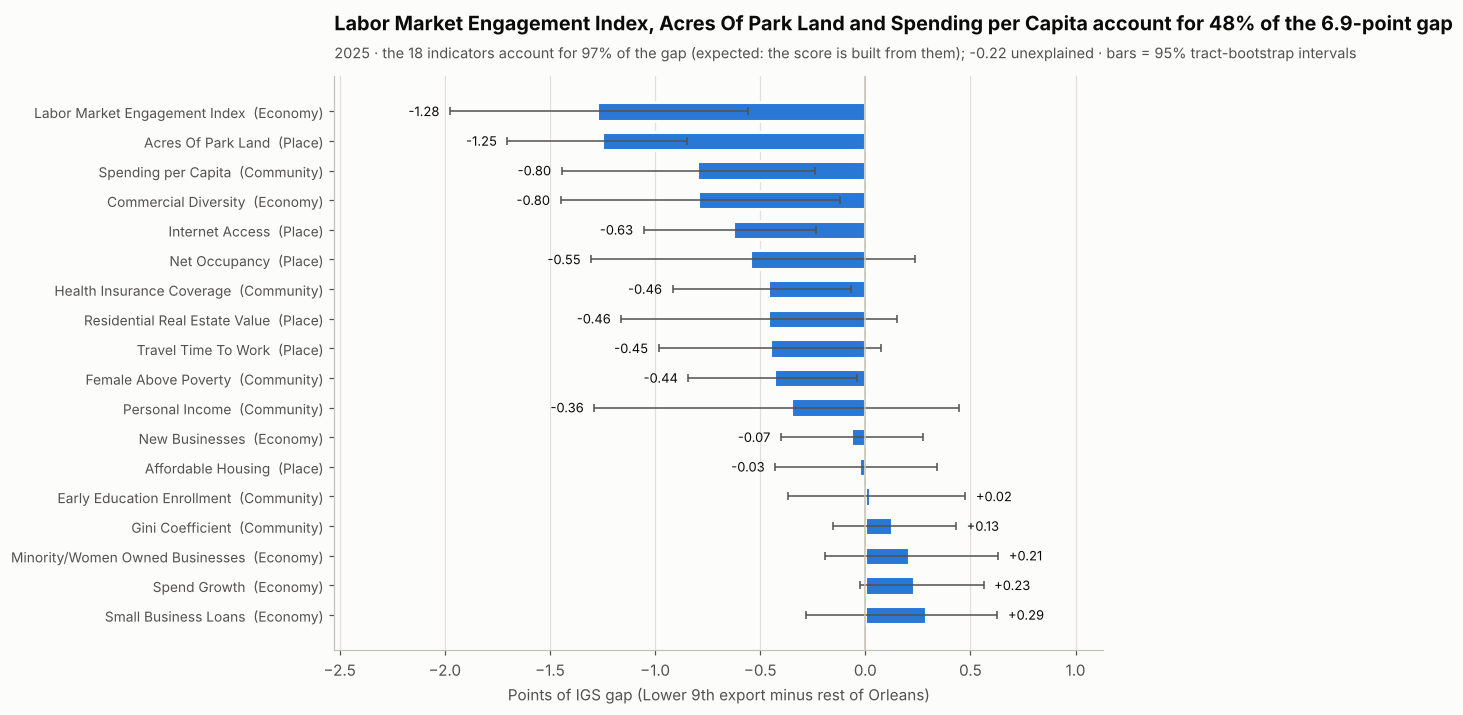

In [29]:
t = tbl.sort_values("points").reset_index(drop=True)                        # most negative first -> top of the chart
yy = np.arange(len(t))[::-1]
fig, ax = plt.subplots(figsize=(11, 6.6))
ax.barh(yy, t["points"], 0.62, color=BLUE, edgecolor=SURFACE, linewidth=2,
        xerr=[(t["points"] - t["ci_lo"]).clip(lower=0), (t["ci_hi"] - t["points"]).clip(lower=0)], error_kw={"ecolor": INK2, "lw": 1, "capsize": 2.5})
for y_, r in zip(yy, t.itertuples()):
    right = r.points >= 0
    ax.text((r.ci_hi if right else r.ci_lo) + (0.05 if right else -0.05), y_, f"{r.points:+.2f}", va="center", ha="left" if right else "right", fontsize=8.5)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(yy); ax.set_yticklabels([f"{a}  ({b})" for a, b in zip(t["indicator"], t["pillar"])], fontsize=9)
ax.grid(axis="y", visible=False); ax.set_xlim(t["ci_lo"].min() - 0.55, t["ci_hi"].max() + 0.5)
ax.set_xlabel("Points of IGS gap (Lower 9th export minus rest of Orleans)")
top3 = t.head(3); share3 = top3["points"].sum() / gap
headline(ax, f"{top3.indicator[0]}, {top3.indicator[1]} and {top3.indicator[2]} account for {share3:.0%} of the {abs(gap):.1f}-point gap",
         f"{YEAR} · the 18 indicators account for {contrib.sum()/gap:.0%} of the gap (expected: the score is built from them); {delta:+.2f} unexplained · bars = 95% tract-bootstrap intervals")
plt.tight_layout(); plt.show()

### Fig 9 — By pillar, and what closing the biggest indicator gaps would do
Left: contributions rolled up to pillars (more stable than single indicators, because indicators within a pillar are correlated). Right: the gap that would remain if the Lower 9th export matched the rest of Orleans on its largest shortfalls, one indicator at a time. This is an **accounting what-if**, not a forecast of what an intervention would achieve.

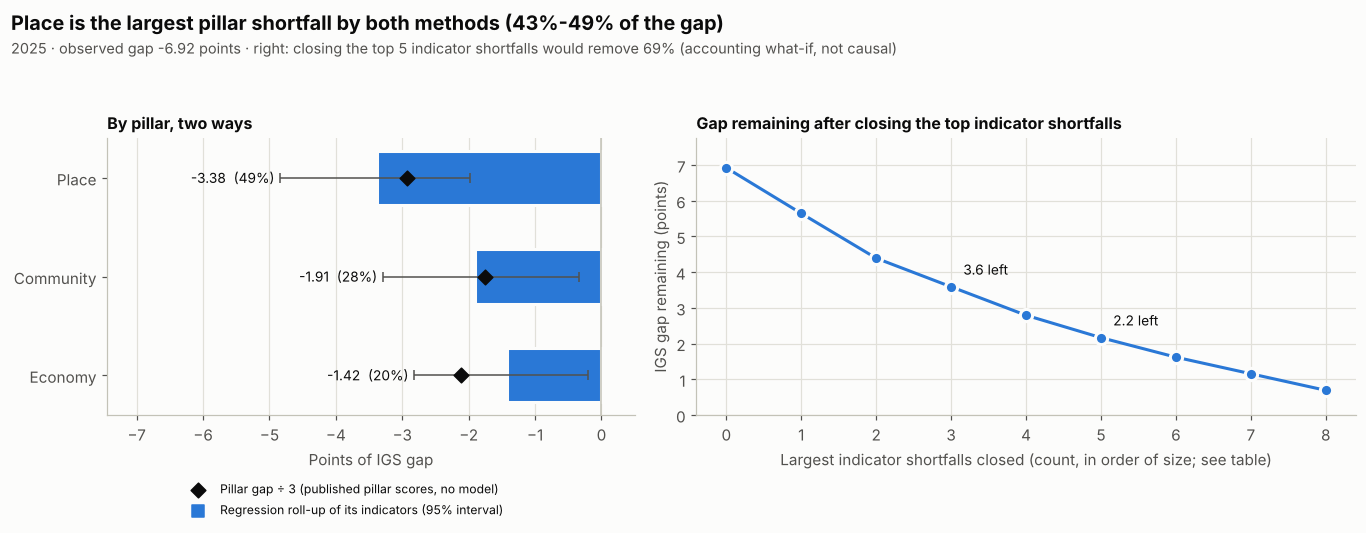

,closed so far,gap remaining,share of gap removed
0,none,6.92,0.00
1,Labor Market Engagement Index,5.65,0.18
2,Acres Of Park Land,4.39,0.37
3,Spending per Capita,3.59,0.48
4,Commercial Diversity,2.79,0.60
5,Internet Access,2.17,0.69
6,Net Occupancy,1.62,0.77
7,Health Insurance Coverage,1.16,0.83
8,Residential Real Estate Value,0.69,0.90


In [30]:
pcols = {"Place": "place", "Economy": "economy", "Community": "community"}
assert all(v in d25.columns for v in pcols.values()), "pillar columns missing from the clean file"
simple = pd.Series({p: (d25.loc[d25.area_group == STUDY, c].mean() - d25.loc[d25.area_group == REST, c].mean()) / 3 for p, c in pcols.items()})
neg = t[t.points < 0].sort_values("points")
K = min(8, len(neg))
remaining = [abs(gap)] + [abs(gap) + neg["points"].iloc[:k].sum() for k in range(1, K + 1)]   # points are negative, so adding them shrinks the gap
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
po = pil.sort_values(); yy2 = np.arange(len(po))[::-1]
ax.barh(yy2, po.values, 0.55, color=BLUE, edgecolor=SURFACE, linewidth=2,
        xerr=[(po - ci_p.loc[po.index, "lo"]).values, (ci_p.loc[po.index, "hi"] - po).values], error_kw={"ecolor": INK2, "lw": 1, "capsize": 3})
for y_, (p_, v) in zip(yy2, po.items()): ax.text(ci_p.loc[p_, "lo"] - 0.08, y_, f"{v:+.2f}  ({v/gap:.0%})", va="center", ha="right", fontsize=9)
ax.scatter(simple.reindex(po.index).values, yy2, marker="D", s=46, color=INK, zorder=4, label="Pillar gap ÷ 3 (published pillar scores, no model)")
ax.scatter([], [], marker="s", s=60, color=BLUE, label="Regression roll-up of its indicators (95% interval)")
ax.axvline(0, color=AXIS, lw=1); ax.set_yticks(yy2); ax.set_yticklabels(po.index); ax.grid(axis="y", visible=False)
ax.set_xlim(ci_p["lo"].min() - 2.6, 0.5); ax.set_xlabel("Points of IGS gap"); ax.set_title("By pillar, two ways", fontsize=10.5, loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.2), fontsize=8, ncol=1)
ax = axes[1]; ks = np.arange(K + 1)
ax.plot(ks, remaining, color=BLUE, lw=2, marker="o", ms=8, markeredgecolor=SURFACE, markeredgewidth=2)
for k_ in (3, 5):
    if k_ <= K: ax.annotate(f"{remaining[k_]:.1f} left", (k_, remaining[k_]), textcoords="offset points", xytext=(8, 8), fontsize=9)
ax.set_ylim(0, abs(gap) * 1.12); ax.set_xticks(ks)
ax.set_xlabel("Largest indicator shortfalls closed (count, in order of size; see table)"); ax.set_ylabel("IGS gap remaining (points)")
ax.set_title("Gap remaining after closing the top indicator shortfalls", fontsize=10.5, loc="left")
lo_s, hi_s = sorted([po.iloc[0] / gap, simple.min() / simple.sum()])
same_top = po.index[0] == simple.idxmin()
fig.suptitle((f"{po.index[0]} is the largest pillar shortfall by both methods ({lo_s:.0%}-{hi_s:.0%} of the gap)" if same_top
              else f"The two methods disagree on the largest pillar ({po.index[0]} vs {simple.idxmin()})"), x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, f"{YEAR} · observed gap {gap:+.2f} points · right: closing the top 5 indicator shortfalls would remove {1 - remaining[min(5, K)]/abs(gap):.0%} (accounting what-if, not causal)", fontsize=9.5, color=INK2)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()
display(pd.DataFrame({"closed so far": ["none"] + list(neg["indicator"].iloc[:K]), "gap remaining": np.round(remaining, 2),
                      "share of gap removed": np.round(1 - np.array(remaining) / abs(gap), 2)}))

### Robustness — does the story depend on the choices above?
Three alternatives: **(a)** complete cases only (tracts with no missing indicator), **(b)** pooled 2021–2025 with year effects, and **(c)** the simple pillar split from Phase II (pillar gap ÷ 3), which needs no regression.

In [31]:
def summarize(label, d, X, extra=None):
    c, dl, r = decompose(d, X) if extra is None else extra
    g = d.loc[d.area_group == STUDY, "igs"].mean() - d.loc[d.area_group == REST, "igs"].mean()
    p = pillar_sums(c)
    return c, {"sample": label, "tracts/rows": len(d), "gap": g, "explained": c.sum(), "unexplained": dl, "R2": r,
               "Place": p["Place"], "Economy": p["Economy"], "Community": p["Community"],
               "top 3": ", ".join(pretty(i) for i in c.sort_values().index[:3])}

rows = [{"sample": f"Main: {YEAR}, imputed", "tracts/rows": len(d25), "gap": gap, "explained": contrib.sum(), "unexplained": delta, "R2": r2,
         **pil.to_dict(), "top 3": ", ".join(pretty(i) for i in contrib.sort_values().index[:3])}]
# (a) complete cases, same year
cc = d25.dropna(subset=IND).reset_index(drop=True)
c_a, r_a = summarize(f"(a) {YEAR}, complete cases only", cc, cc[IND]); rows.append(r_a)
# (b) pooled 2021-2025, imputed within each year, year effects
pool = df[(df.year >= 2021) & df.area_group.isin([STUDY, REST]) & df.igs.notna()].reset_index(drop=True)
Xp = pd.concat([impute_indicators(pool[pool.year == y]) for y in sorted(pool.year.unique())]).loc[pool.index] if False else None
parts = [impute_indicators(pool[pool.year == y]) for y in sorted(pool.year.unique())]
Xp = pd.concat(parts).sort_index()
yd = pd.get_dummies(pool.year, drop_first=True).astype(float)
g_ = (pool.area_group == STUDY).to_numpy().astype(float)
A = np.column_stack([np.ones(len(pool)), Xp.to_numpy(), g_, yd.to_numpy()]); co = np.linalg.lstsq(A, pool.igs.to_numpy(float), rcond=None)[0]
beta_p = pd.Series(co[1:1 + len(IND)], index=IND); c_b = beta_p * (Xp[g_ == 1].mean() - Xp[g_ == 0].mean())
r2_b = 1 - (pool.igs.to_numpy() - A @ co).var() / pool.igs.var()
gp = pool.loc[pool.area_group == STUDY, "igs"].mean() - pool.loc[pool.area_group == REST, "igs"].mean()
pb = pillar_sums(c_b)
rows.append({"sample": "(b) pooled 2021-2025, year effects", "tracts/rows": len(pool), "gap": gp, "explained": c_b.sum(), "unexplained": co[1 + len(IND)], "R2": r2_b,
             **pb.to_dict(), "top 3": ", ".join(pretty(i) for i in c_b.sort_values().index[:3])})
rob = pd.DataFrame(rows).set_index("sample")
display(rob.round(2))
print(f"Rank agreement of indicator contributions with the main result: (a) Spearman {contrib.rank().corr(c_a.rank()):.2f}, (b) Spearman {contrib.rank().corr(c_b.rank()):.2f}")

# (c) Phase II style check: pillar score gap / 3, no regression
chk = pd.DataFrame({"regression roll-up": pil, "pillar gap / 3 (no model)": simple})
chk.loc["Total"] = chk.sum()
print("\nPillar contributions to the gap, two ways (IGS is about the average of its three pillars):"); display(chk.round(2))

,tracts/rows,gap,explained,unexplained,R2,Place,Economy,Community,top 3
sample,,,,,,,,,
"Main: 2025, imputed",182,-6.92,-6.70,-0.22,0.97,-3.38,-1.42,-1.91,"Labor Market Engagement Index, Acres Of Park Land, Spending per Capita"
"(a) 2025, complete cases only",135,-7.79,-7.48,-0.31,0.97,-4.36,-0.94,-2.18,"Labor Market Engagement Index, Acres Of Park Land, Net Occupancy"
"(b) pooled 2021-2025, year effects",910,-6.50,-6.05,-0.45,0.96,-2.66,-2.20,-1.19,"Labor Market Engagement Index, Acres Of Park Land, Internet Access"


Rank agreement of indicator contributions with the main result: (a) Spearman 0.95, (b) Spearman 0.85

Pillar contributions to the gap, two ways (IGS is about the average of its three pillars):


,regression roll-up,pillar gap / 3 (no model)
Place,-3.38,-2.93
Economy,-1.42,-2.11
Community,-1.91,-1.75
Total,-6.70,-6.79


In [32]:
# ---- Findings (computed) ----
top = tbl.sort_values("points").head(3)
pred_top5 = list(ind_imp.index[:5])                                  # Part 2: indicators the forecast leans on most
gap_top5 = list(tbl.sort_values("points").indicator.head(5))         # Part 3: indicators that explain the most of the gap
overlap = [x for x in gap_top5 if x in pred_top5]
big = pil.idxmin()
print(f"1. Size of the gap. In {YEAR} the Lower 9th export scores {abs(gap):.1f} points below the rest of Orleans (IGS {d25.loc[d25.area_group == STUDY, 'igs'].mean():.1f} vs {d25.loc[d25.area_group == REST, 'igs'].mean():.1f}).")
print(f"2. Fit. The 18 indicators account for {contrib.sum()/gap:.0%} of it ({contrib.sum():+.2f} points), as expected because the score is built from them; {delta:+.2f} points are not explained by indicator levels. The informative part is how the gap is divided.")
print(f"3. By pillar. " + "; ".join(f"{p} {v:+.2f} ({v/gap:.0%})" for p, v in pil.sort_values().items()) + f". Largest: {big}.")
print("4. Top indicator shortfalls. " + "; ".join(f"{r.indicator} {r.points:+.2f} (95% CI {r.ci_lo:+.2f} to {r.ci_hi:+.2f})" for r in top.itertuples()) + ".")
print(f"5. What-if. Closing the five largest indicator shortfalls to the rest-of-Orleans level would remove {1 - remaining[min(5, K)]/abs(gap):.0%} of the gap ({remaining[min(5, K)]:.1f} of {abs(gap):.1f} points remain).")
print(f"6. Robustness. Complete-case and pooled-year versions agree on indicator order (Spearman {contrib.rank().corr(c_a.rank()):.2f} and {contrib.rank().corr(c_b.rank()):.2f}); the pillar with the largest share is {rob[PILLARS].iloc[0].idxmin()} (main), {rob[PILLARS].iloc[1].idxmin()} (a), {rob[PILLARS].iloc[2].idxmin()} (b).")
print(f"7. Prediction vs. explanation. The forecast leans most on {pil_imp.index[0]} indicators (Part 2), while the gap is largest in {big}. Top-5 overlap between the two lists: {len(overlap)} of 5" + (f" ({', '.join(overlap)})." if overlap else "."))
order_reg, order_dir = list(pil.sort_values().index), list(simple.sort_values().index)
print(f"8. Pillar methods. Regression roll-up order: {' > '.join(order_reg)}; published-pillar order (gap/3): {' > '.join(order_dir)}. " + ("Same order." if order_reg == order_dir else "The orders differ below the first place, so quote the direct pillar split for pillar-level claims and the regression only for indicator-level claims."))

1. Size of the gap. In 2025 the Lower 9th export scores 6.9 points below the rest of Orleans (IGS 35.7 vs 42.6).
2. Fit. The 18 indicators account for 97% of it (-6.70 points), as expected because the score is built from them; -0.22 points are not explained by indicator levels. The informative part is how the gap is divided.
3. By pillar. Place -3.38 (49%); Community -1.91 (28%); Economy -1.42 (20%). Largest: Place.
4. Top indicator shortfalls. Labor Market Engagement Index -1.28 (95% CI -1.98 to -0.56); Acres Of Park Land -1.25 (95% CI -1.70 to -0.85); Spending per Capita -0.80 (95% CI -1.44 to -0.24).
5. What-if. Closing the five largest indicator shortfalls to the rest-of-Orleans level would remove 69% of the gap (2.2 of 6.9 points remain).
6. Robustness. Complete-case and pooled-year versions agree on indicator order (Spearman 0.95 and 0.85); the pillar with the largest share is Place (main), Place (a), Place (b).
7. Prediction vs. explanation. The forecast leans most on Economy in

### Limits to state in the report
- **High explained share is by construction.** The IGS is calculated from these indicators, so they account for almost all of the gap; what matters is how the gap is divided, and how uncertain each piece is.
- **Pillar-level claims.** The pillar scores are published, so for pillar-level statements use the direct split (pillar gap ÷ 3). The regression roll-up recovers the hidden weights from the data and can rank the smaller pillars differently (see Fig 9).
- **Accounting, not causation.** The decomposition shows where the points are lost under the IGS formula; it does not show that raising an indicator would cause the score to rise, or that doing so is feasible in these tracts.
- **Pooled slopes.** The regression assumes the same indicator weights in both groups. With 33 Lower 9th tracts and 18 indicators there is not enough data to estimate separate slopes; the small unexplained term suggests the pooled weights fit both groups well.
- **Correlated indicators.** Indicators move together (largest pairwise correlation is about 0.7), so single-indicator contributions are less certain than pillar totals. Lean on the pillar view and the ranking agreement in the robustness table.
- **Imputation.** About a fifth of the Minority/Women Owned Businesses values and a tenth of the Spend Growth and Spending per Capita values are filled in by a model. Complete-case results are shown for comparison; they drop a larger share of Lower 9th tracts than of the rest of Orleans.
- **Study area.** "Lower 9th export" is the set of tracts the IGS dashboard returned for the Lower Ninth Ward (33 scored tracts, including one in St. Bernard Parish), not a verified neighborhood boundary.

### Handoff to Phase IV (briefing)
The story in three steps: **(1)** the Lower 9th export trails the rest of Orleans (Part 1); **(2)** the shortfall is concentrated in the pillar and indicators shown in Fig 8–9, and the printed what-if shows how much of the gap the biggest shortfalls account for (Part 3); **(3)** the forecast says the gap persists at about the same size next year, so it will not close on its own (Part 2). Use the printed findings for exact numbers.